<a href="https://colab.research.google.com/github/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting/blob/main/Chapter03_Zero_Shot_Forecasting/10_baselines.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 10 · Baselines: statistical, machine-learning and deep-learning models

*Hands-On Open-Source Foundation Models for Time Series Forecasting*, Chapter 3: Zero-Shot Forecasting in Practice

This notebook forecasts the same splits as the foundation models with sixteen classical and supervised
baselines. The statistical ones are the naive and seasonal naive rules, the random walk with drift (RWD), AR, ARIMA,
ARIMAX, ARDL, VAR and VARX, from the statsmodels and statsforecast libraries. The learned ones are LightGBM,
XGBoost, CatBoost, NHiTS, TFT, DLinear and TiDE, all seven from the Darts library. The statistical models choose
their orders by AIC or AICc at every forecast origin; the learned models choose their hyperparameters with a short
Optuna search, starting from the default setting, on validation windows inside the training data.

#### Why baselines matter

A zero-shot model is only useful if it beats what a forecaster would otherwise do. The naive rules tell us whether
a model adds anything at all; the statistical and supervised models tell us whether skipping training costs
accuracy. Unlike the foundation models, every model here is fitted and tuned on our data, so the comparison is
"pre-trained and untouched" against "trained and tuned on this series". The test windows play no part in any of
that fitting or tuning.

The datasets are D1, D2, D3 and D4, with the splits of Notebook 04.

**What you will learn**

- the equation behind every classical baseline, and how covariates without future values are handled
- how to tune without leaking the test data: information criteria at every origin, an Optuna search on
  validation windows for learned models, and how to widen that search yourself
- how gradient-boosted trees and neural networks are set up for direct multi-step forecasting in Darts
- which baselines are hard to beat on each dataset

| Environment and compute | |
|---|---|
| Python | 3.12 (tested) |
| Packages | [`requirements/env-baselines.txt`](requirements/env-baselines.txt) (pinned) |
| Hardware | CPU; a CUDA GPU, when present, trains the networks, XGBoost and CatBoost |
| Network | none |
| Run time, quick check (default) | about 10 min on 4 CPU cores |
| Run time, `FULL_RUN = True` | about 85 min, the hyperparameter searches included, measured with 2 CPU cores (as on Colab's free tier); more cores or a GPU make it faster |

**How to run this notebook**

- **Google Colab:** choose *Runtime > Run all*. The first code cell fetches this chapter's folder and installs `requirements/env-baselines.txt`
  with uv (a few minutes the first time). If it says it is restarting the session, wait, then choose *Runtime > Run all*
  again. To use your own copy on Google Drive, set `DRIVE_COPY` in that cell to the folder's path. A GPU runtime
  is not needed; if you pick one, the models use it.
- **Your own computer (Cursor, VS Code or Jupyter):** create the environment once with
  `uv venv .venv-baselines -p 3.12 && uv pip install -p .venv-baselines -r requirements/env-baselines.txt`
  (or `python3.12 -m venv .venv-baselines` and `pip install -r ...`), open this folder, choose the `.venv-baselines` kernel
  and run all cells.

In [1]:
# Setup: find this chapter's folder (on Colab: fetch it and install this notebook's environment)
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules


def is_chapter(d):
    return (Path(d) / "src" / "ch03_dataprep" / "__init__.py").is_file()


if IN_COLAB:  # get this chapter's folder and install this notebook's environment
    import shutil

    CHAPTER = "Chapter03_Zero_Shot_Forecasting"   # this chapter's folder in the book's repository
    DRIVE_COPY = ""   # optional: path of your own copy of this folder on Google Drive (skips GitHub)
    BOOK = Path("/content/book")

    def chapter_dir():  # this chapter's folder under /content/book, or None until it is there
        return next((d for d in (BOOK / CHAPTER, BOOK) if is_chapter(d)), None)

    def find_in_drive(top="/content/drive/MyDrive", depth=6):  # the copies of CHAPTER, shallowest first
        level = [top]
        for _ in range(depth):
            subdirs = []
            for d in level:
                try:
                    subdirs += [e.path for e in os.scandir(d) if e.is_dir() and not e.name.startswith(".")]
                except OSError:
                    pass
            hits = [d for d in subdirs if Path(d).name == CHAPTER and is_chapter(d)]
            if hits:
                return hits
            level = subdirs
        return []

    def local_only(d, names):  # what not to copy from Drive: local environments, caches, downloaded data
        return [n for n in names if n.startswith(".venv") or n == "__pycache__" or (d.endswith("/data") and n == "raw")]

    if chapter_dir() is None and not DRIVE_COPY:    # 1) clone the book's repository from GitHub
        shutil.rmtree(BOOK, ignore_errors=True)
        !GIT_TERMINAL_PROMPT=0 git clone -q --depth 1 https://github.com/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting /content/book
    if chapter_dir() is None:                       # 2) not on GitHub (yet): copy it from your Google Drive
        from google.colab import drive
        drive.mount("/content/drive")
        if not DRIVE_COPY:
            print(f"{CHAPTER} is not on GitHub: searching My Drive for it (set DRIVE_COPY above to skip this)")
            hits = find_in_drive()
            if len(hits) > 1:
                raise FileExistsError(f"several copies of {CHAPTER} in My Drive: {hits}. Set DRIVE_COPY to one.")
            DRIVE_COPY = hits[0] if hits else ""
        if DRIVE_COPY and not is_chapter(DRIVE_COPY):
            raise FileNotFoundError(f"DRIVE_COPY = {DRIVE_COPY!r} is not this chapter's folder (no src/ch03_dataprep)")
        if DRIVE_COPY:
            print(f"copying {DRIVE_COPY} to {BOOK / CHAPTER} ...")
            shutil.rmtree(BOOK, ignore_errors=True)
            shutil.copytree(DRIVE_COPY, BOOK / "partial-copy", ignore=local_only)
            (BOOK / "partial-copy").rename(BOOK / CHAPTER)    # only a finished copy gets the chapter's name
            print(f"copied {sum(len(files) for _, _, files in os.walk(BOOK / CHAPTER)):,} files")
    if chapter_dir() is None:
        raise FileNotFoundError(f"{CHAPTER} is not in the book's GitHub repository or in your Google Drive. "
                                "Upload the folder to Drive, or set DRIVE_COPY above to its path there.")
    os.chdir(chapter_dir())
    import importlib.metadata as md

    def key(name):  # package installers treat huggingface_hub and huggingface-hub as one package
        return name.lower().replace("_", "-").replace(".", "-")

    def versions():  # the version of every installed package, as Python finds it (first copy on sys.path)
        found = {}
        for d in md.distributions():
            found.setdefault(key(d.metadata["Name"]), d.version)
        return found

    before = versions()
    # Install with uv: it downloads and installs packages in parallel, several times faster than pip. Colab comes
    # with uv (installed here if not). The settings point uv at Colab's own Python (Colab has no virtual environment)
    # and drop install constraints that Colab may have left over from building its image. Each uv line falls back
    # to pip if uv fails.
    if shutil.which("uv") is None:
        %pip install -q uv
    for name in ("UV_CONSTRAINT", "UV_BUILD_CONSTRAINT", "UV_PRERELEASE"):
        os.environ.pop(name, None)
    os.environ.update(UV_PYTHON=sys.executable, UV_SYSTEM_PYTHON="1", UV_BREAK_SYSTEM_PACKAGES="1")
    # keep Colab's own torch (with CUDA) and Jupyter; install everything else this notebook needs
    !grep -vE "^(torch|jupyter|ipykernel|nbclient|nbformat|pytest|nbval|ruff)==" requirements/env-baselines.txt > /tmp/requirements-colab.txt
    !uv pip install -q -r /tmp/requirements-colab.txt || {sys.executable} -m pip install -q -r /tmp/requirements-colab.txt
    # stop here if neither uv nor pip could install everything; the error message is above
    try:
        from packaging.version import Version
    except ImportError:
        Version = str
    missing = []
    for line in open("/tmp/requirements-colab.txt"):
        name, _, pin = line.split("#")[0].strip().partition("==")
        if not pin:
            continue
        try:
            installed = md.version(name.split("[")[0])
        except md.PackageNotFoundError:
            installed = None
        if installed is None or Version(installed) != Version(pin):
            missing.append(f"{name}=={pin}")
    if missing:
        raise RuntimeError(f"Could not install {', '.join(missing)}; scroll up for its error. If it was a network error, "
                           "run this cell again. If uv or pip tried to build a package from source, this runtime's Python is "
                           "too new for this notebook: see the How to run section at the top.")
    # Colab comes with torchvision, torchaudio, torchcodec and transformers, and torchmetrics imports some of them
    # whenever they are installed. If the install changed a package they depend on (some environments replace torch or
    # huggingface-hub), they no longer load. This notebook does not need them, so remove those that broke.
    try:
        from packaging.requirements import Requirement
    except ImportError:  # Colab has packaging; pip always carries its own copy
        from pip._vendor.packaging.requirements import Requirement

    now = versions()
    changed = {name for name, version in now.items() if before.get(name) != version}
    if "torch" in changed:
        # This notebook needs another torch than Colab's (Notebook 06: 2.4.1). Replacing torch can leave some of the
        # old torch's files behind, and Python then loads them ("cannot import name ... from torch.onnx"). Reinstall
        # it into clean folders (uv takes it from its cache, so nothing downloads twice).
        print(f"Replacing Colab's torch {before.get('torch')} with {now['torch']}: reinstalling it into clean folders ...")
        torch_pin = now["torch"]
        site = Path(md.distribution("torch").locate_file(""))
        folders = [site / m for m, names in md.packages_distributions().items()
                   if "torch" in names and m.isidentifier() and (site / m).is_dir()]
        !uv pip uninstall -q torch || {sys.executable} -m pip uninstall -q -y torch
        for folder in folders:
            shutil.rmtree(folder, ignore_errors=True)
        !uv pip install -q torch=={torch_pin} || {sys.executable} -m pip install -q torch=={torch_pin}
        now = versions()

    def requirements(dist):  # the requirements of an installed package that apply here
        found = []
        for line in md.requires(dist) or []:
            try:
                r = Requirement(line)
                if r.marker is None or r.marker.evaluate({"extra": ""}):
                    found.append(r)
            except Exception:  # a line this version of packaging cannot read
                pass
        return found

    def broken(dist):  # Colab's copy of dist, and the install changed something it needs
        if dist not in now or dist in changed:
            return False  # not installed, or installed by this notebook
        if "torch" in changed:
            return True   # Colab built and tested it with its own torch
        return any(key(r.name) in changed and not r.specifier.contains(now[key(r.name)], prereleases=True)
                   for r in requirements(dist))

    misfits = [d for d in ("torchvision", "torchaudio", "torchcodec", "transformers") if broken(d)]
    if misfits:
        print(f"Removing unused packages that this install broke: {', '.join(misfits)}")
        !uv pip uninstall -q {" ".join(misfits)} || {sys.executable} -m pip uninstall -q -y {" ".join(misfits)}
    # Colab imports some packages (numpy, pandas, torch, ...) before this cell finishes. If the install replaced one
    # of them, Python keeps the old version in memory and mixes it with the new files on disk (errors such as
    # "cannot import name ... from torch.onnx"), so restart once to load the new version.
    after = versions()
    stale = sorted(m for m, names in md.packages_distributions().items() if m in sys.modules
                   and any(before.get(key(n), after.get(key(n))) != after.get(key(n)) for n in names))
    for m in ("torch", "numpy", "pandas", "scipy"):  # also catches a session that was not restarted after an earlier run
        loaded = str(getattr(sys.modules.get(m), "__version__", ""))
        if loaded and m not in stale and loaded.split("+")[0] != after.get(m, loaded).split("+")[0]:
            stale.append(m)
    restarted_from = Path("/tmp/ch03_restart_pid")   # the session this cell last asked to restart
    if stale and restarted_from.is_file() and restarted_from.read_text() == str(os.getpid()):
        raise SystemExit(f"The session has not restarted and still has the old {', '.join(stale)} in memory. "
                         "Choose Runtime > Restart session, then Runtime > Run all.")
    if stale:
        restarted_from.write_text(str(os.getpid()))
        print(f"The install updated {', '.join(stale)}, which Colab had already loaded: restarting the session.")
        from IPython import get_ipython
        kernel = getattr(get_ipython(), "kernel", None)
        if kernel is not None:
            kernel.do_shutdown(True)
        raise SystemExit("When the session has restarted, choose Runtime > Run all again; the first cell then finishes quickly. "
                         "If it has not restarted after a few seconds, choose Runtime > Restart session, then Runtime > Run all.")
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if is_chapter(p))
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)
DATA, RESULTS, INPUT = ROOT / "data", ROOT / "results", ROOT / "input_timeseries"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"chapter folder: {ROOT}  |  Python {sys.version.split()[0]}  |  Colab: {IN_COLAB}  |  device: {DEVICE}")

chapter folder: /home/user/v3  |  Python 3.12.3  |  Colab: False  |  device: cpu


#### Quick check or full run

With `FULL_RUN = False`, the default, every baseline makes a quick check on the fixed-origin window at the two
shortest horizons, and the analysis reads the stored full results. In the quick check the statistical models still
choose their orders at the origin; the learned models skip the search, reuse the hyperparameters the full run chose
(stored in `results/tuning/`) and train for one epoch or 40 trees. `FULL_RUN = True` runs the Optuna searches again
(with `SPACE` and `N_TRIALS` of Section 2), refits everything and forecasts every horizon and window.

In [2]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from ch03_dataprep.plotting import set_style
from ch03_zeroshot.architectures import figure
from ch03_zeroshot.baselines import (BASELINES, chosen_orders, order_summary, run_baseline, tuning_design,
                                     tuning_results, tuning_summary)
from ch03_zeroshot.data import load_frame
from ch03_zeroshot.metrics import aggregate
from ch03_zeroshot.report import (cost_table, forecast_gallery, gain_tables, load_forecasts, run_table,
                                  scores_cached, show_forecast_tables, show_gains, show_horizon_table)
from ch03_zeroshot.runner import run_summary
from ch03_zeroshot.tables import display_names

warnings.filterwarnings("ignore")
set_style()
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)
FULL_RUN = False
DATASETS = ['D1', 'D2', 'D3', 'D4']
KEYS = list(BASELINES)
NAMES = display_names()
FIG = RESULTS / "figures" / "architectures"
FIG.mkdir(parents=True, exist_ok=True)


def run(key):
    """Fit one baseline (quick check or full run; learned models use SPACE and N_TRIALS of Section 2) and show
    what it read, the setting it used and how long it took."""
    log = run_baseline(key, DATASETS, ROOT, smoke=not FULL_RUN, verbose=False, space=SPACE.get(key),
                       n_trials=N_TRIALS.get(key))
    return run_table(log, DATASETS)

## 1 · The baselines

| Baseline | Family | Covariates it uses | Runs on | Source |
|---|---|---|---|---|
| Naive (RW) | statistical | none | D1, D2, D3, D4 | random walk: last value |
| Seasonal naive | statistical | none | D1, D2, D3, D4 | Hyndman and Athanasopoulos (2021), Sec. 5.2 |
| RWD | statistical | none | D1, D2, D3, D4 | random walk with drift; Hyndman and Athanasopoulos (2021), Sec. 5.2 |
| AR | statistical | none | D1, D2, D3, D4 | statsmodels AutoReg, order by AIC (ar_select_order) |
| ARIMA | statistical | none | D1, D2, D3, D4 | Hyndman and Khandakar (2008); statsforecast AutoARIMA |
| ARIMAX | statistical | past + known-future | D2, D4 | regression with ARIMA errors; statsforecast AutoARIMA with X |
| ARDL | statistical | past + known-future | D2, D4 | Pesaran and Shin (1998); statsmodels ARDL |
| VAR | statistical | none | D3 | Sims (1980); statsmodels VAR, order by AIC |
| VARX | statistical | past | D4 | VAR with the drivers; statsmodels VAR |
| LightGBM | machine learning | past + known-future | D1, D2, D3, D4 | Ke et al. (2017); Darts LightGBMModel |
| XGBoost | machine learning | past + known-future | D1, D2, D3, D4 | Chen and Guestrin (2016); Darts XGBModel |
| CatBoost | machine learning | past + known-future | D1, D2, D3, D4 | Prokhorenkova et al. (2018); Darts CatBoostModel |
| NHiTS | deep learning | past | D1, D2, D3, D4 | Challu et al. (2023); Darts NHiTSModel |
| TFT | deep learning | past + known-future | D1, D2, D3, D4 | Lim et al. (2021); Darts TFTModel |
| DLinear | deep learning | past + known-future | D1, D2, D3, D4 | Zeng et al. (2023); Darts DLinearModel |
| TiDE | deep learning | past + known-future | D1, D2, D3, D4 | Das et al. (2023); Darts TiDEModel |

#### The code

The whole module, [`src/ch03_zeroshot/baselines.py`](src/ch03_zeroshot/baselines.py), is shown here so you can
see exactly how each baseline is fitted and tuned. Statistical models are refitted at every origin on the same
context a foundation model reads. Learned models are tuned and trained once on the data before the earliest test
window and then forecast each window from its own origin.

Covariates need care. A direct model reads known-future covariates over its whole output, which for the shorter
horizons runs past the end of the data; D2's calendar terms are simply computed for those dates (`extend_calendar`),
since they are functions of the date. Past-only covariates have no future values. ARIMAX and ARDL read them one
step late, so the first forecast step uses their last observed value and later steps use AutoARIMA forecasts of them
made from the context. The learned models read them only as lags.

In [3]:
import json
import logging
import os
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

from ch03_zeroshot.data import SEASON, build_inputs, context_cap, input_plan, load_frame, load_manifest, to_long

warnings.filterwarnings("ignore")

# key: name, family, covariates it can use, datasets it runs on (None = all), source
BASELINES = {
    "naive": {"name": "Naive (RW)", "family": "statistical", "exog": "none", "on": None,
              "source": "random walk: last value"},
    "snaive": {"name": "Seasonal naive", "family": "statistical", "exog": "none", "on": None,
               "source": "Hyndman and Athanasopoulos (2021), Sec. 5.2"},
    "rwd": {"name": "RWD", "family": "statistical", "exog": "none", "on": None,
            "source": "random walk with drift; Hyndman and Athanasopoulos (2021), Sec. 5.2"},
    "ar": {"name": "AR", "family": "statistical", "exog": "none", "on": None,
           "source": "statsmodels AutoReg, order by AIC (ar_select_order)"},
    "arima": {"name": "ARIMA", "family": "statistical", "exog": "none", "on": None,
              "source": "Hyndman and Khandakar (2008); statsforecast AutoARIMA"},
    "arimax": {"name": "ARIMAX", "family": "statistical", "exog": "past + known-future", "on": ["D2", "D4"],
               "source": "regression with ARIMA errors; statsforecast AutoARIMA with X"},
    "ardl": {"name": "ARDL", "family": "statistical", "exog": "past + known-future", "on": ["D2", "D4"],
             "source": "Pesaran and Shin (1998); statsmodels ARDL"},
    "var": {"name": "VAR", "family": "statistical", "exog": "none", "on": ["D3", "B2"],
            "source": "Sims (1980); statsmodels VAR, order by AIC"},
    "varx": {"name": "VARX", "family": "statistical", "exog": "past", "on": ["D4"],
             "source": "VAR with the drivers; statsmodels VAR"},
    "lightgbm": {"name": "LightGBM", "family": "machine learning", "exog": "past + known-future", "on": None,
                 "source": "Ke et al. (2017); Darts LightGBMModel"},
    "xgboost": {"name": "XGBoost", "family": "machine learning", "exog": "past + known-future", "on": None,
                "source": "Chen and Guestrin (2016); Darts XGBModel"},
    "catboost": {"name": "CatBoost", "family": "machine learning", "exog": "past + known-future", "on": None,
                 "source": "Prokhorenkova et al. (2018); Darts CatBoostModel"},
    "nhits": {"name": "NHiTS", "family": "deep learning", "exog": "past", "on": None,
              "source": "Challu et al. (2023); Darts NHiTSModel"},
    "tft": {"name": "TFT", "family": "deep learning", "exog": "past + known-future", "on": None,
            "source": "Lim et al. (2021); Darts TFTModel"},
    "dlinear": {"name": "DLinear", "family": "deep learning", "exog": "past + known-future", "on": None,
                "source": "Zeng et al. (2023); Darts DLinearModel"},
    "tide": {"name": "TiDE", "family": "deep learning", "exog": "past + known-future", "on": None,
             "source": "Das et al. (2023); Darts TiDEModel"},
}
STATISTICAL = [k for k, v in BASELINES.items() if v["family"] == "statistical"]
LEARNED = [k for k, v in BASELINES.items() if v["family"] != "statistical"]
TRANSFORM = {"D1": None, "D2": None, "D3": "logdiff", "D4": "logdiff", "B1": "diff", "B2": "diff"}
DRIVER_TRANSFORM = {"global_activity": "diff", "usd": "logdiff", "real_rate_10y": "diff"}
TWIN = {"D2": "D1", "D4": "D3"}
TRAIN_ROWS = 4096          # most recent rows used to train a learned model on daily data
SEED = 42


def caps(key):
    """Capabilities in the form data.input_plan expects."""
    e = BASELINES[key]["exog"]
    return {"multivariate": key in ("var", "varx", "lightgbm", "xgboost", "catboost", "nhits", "tft", "dlinear", "tide"),
            "past_covariates": "past" in e, "future_covariates": "known-future" in e or "future" in e}


def runs_on(key, dataset):
    on = BASELINES[key]["on"]
    return on is None or dataset in on


# ------------------------------------------------------------------ transforms
def _fwd(x, how):
    x = np.asarray(x, float)
    if how is None:
        return x
    if how == "logdiff":
        return np.diff(np.log(x), axis=-1)
    return np.diff(x, axis=-1)


def _inv(last, d, how):
    """Integrate forecasts d (..., H) of a transformed series back to levels from the last level."""
    if how is None:
        return d
    last = np.asarray(last, float)[..., None]
    if how == "logdiff":
        return last * np.exp(np.cumsum(d, axis=-1))
    return last + np.cumsum(d, axis=-1)


# ------------------------------------------------------------------ statistical models
_PLUGIN = {}


def _plugin(name, col, origin, x, h):
    """AutoARIMA forecast of a past-only covariate (cached per origin and horizon)."""
    from statsforecast.models import AutoARIMA

    k = (name, col, str(origin), h)
    if k not in _PLUGIN:
        try:
            _PLUGIN[k] = AutoARIMA(season_length=1).forecast(y=np.asarray(x, float), h=h)["mean"]
        except Exception:
            _PLUGIN[k] = np.repeat(float(x[-1]), h)
    return _PLUGIN[k]


def _exog(name, s, h, lag_past=False):
    """Covariates over the context (T, k) and the horizon (h, k): known-future values are real,
    past-only values are plug-in forecasts. With ``lag_past`` a past-only covariate enters one step late
    (x_{t-1} explains y_t), so step 1 reads its last observed value and only steps 2 and later need plug-ins.
    ARIMAX needs this on D2: its wavelet bands add up exactly to the temperature, so at lag 0 the regression
    would be the identity y_t = sum of the bands_t."""
    cols, ctx, fut = [], [], []
    if s.future_covariates is not None:
        T = len(s.target) if np.ndim(s.target) == 1 else s.target.shape[-1]
        for c, row in zip(s.future_cov_names, s.future_covariates):
            cols.append(c)
            ctx.append(row[:T])
            fut.append(row[T:T + h])
    if s.past_covariates is not None:
        for c, row in zip(s.past_cov_names, s.past_covariates):
            cols.append(c)
            if lag_past:
                ctx.append(np.r_[row[0], row[:-1]])          # first row repeats: no value before the data start
                rest = _plugin(name, c, s.item_id.split("|r")[-1] + str(len(row)), row, h - 1) if h > 1 else []
                fut.append(np.r_[row[-1], rest])
            else:
                ctx.append(row)
                fut.append(_plugin(name, c, s.item_id.split("|r")[-1] + str(len(row)), row, h))
    if not cols:
        return None, None
    return np.column_stack(ctx), np.column_stack(fut)




def _ardl(y, X, Xf, h, maxlag, n_known):
    """ARDL(p, q): known-future covariates enter at lags 0..q, past-only covariates at lags 1..q (their value at
    time t is not known when y_t is forecast). Multi-step forecasts still read plug-in values of the past-only
    covariates for steps 2 and later. The orders p and q are chosen by AIC at every origin, on that origin's
    context only (like AR, ARIMA and VAR), so no window's choice can see another window's test data.
    Returns (forecast, chosen order)."""
    from statsmodels.tsa.ardl import ARDL

    cols = [f"x{i}" for i in range(X.shape[1])]
    X, Xf = pd.DataFrame(X, columns=cols), pd.DataFrame(Xf, columns=cols)

    def order(q):
        return {c: list(range(0 if i < n_known else 1, q + 1)) for i, c in enumerate(cols)}

    best = (np.inf, 1, 1)
    for p in range(1, maxlag + 1):
        for q in (1, 2):
            try:   # hold_back=maxlag: every candidate is fitted on the same rows, so their AICs are comparable
                aic = ARDL(y, p, X, order(q), trend="c", hold_back=maxlag).fit().aic
            except Exception:
                continue
            if aic < best[0]:
                best = (aic, p, q)
    p, q = best[1:]
    res = ARDL(y, p, X, order(q), trend="c").fit()
    return np.asarray(res.forecast(h, exog=Xf), float), f"ARDL({p},{q})"


def _var_forecast(Y, h, maxlags, exog=None, exog_future=None):
    """VAR on stationary columns Y (T, k), lag order p by AIC (1..maxlags); returns ((h, k) forecast, p)."""
    from statsmodels.tsa.api import VAR

    model = VAR(Y, exog=exog)
    p = max(1, int(model.select_order(maxlags).aic))
    res = model.fit(p)
    return res.forecast(Y[-p:], h, exog_future=exog_future), p


def _autoarima(y, h, season, X=None, Xf=None):
    """AutoARIMA (Hyndman and Khandakar, 2008): d by repeated KPSS tests, D by a seasonal-strength test, then
    p, q, P and Q by a stepwise search that minimises the AICc. Returns (forecast, chosen model)."""
    from statsforecast.arima import arima_string
    from statsforecast.models import AutoARIMA

    model = AutoARIMA(season_length=season, ic="aicc").fit(np.asarray(y, float), X=X)
    return np.asarray(model.predict(h, X=Xf)["mean"], float), arima_string(model.model_)


def statistical_forecast(key, s, h, name, m, grain):
    """(point forecast (h,) or (V, h), chosen order) of statistical baseline ``key`` for one SeriesInput.

    Every order is chosen by an information criterion on this origin's context only."""
    y = np.asarray(s.target, float)
    if key == "naive":
        return np.repeat(y[-1], h), ""
    if key == "snaive":
        steps = np.arange(h)
        return y[len(y) - m + steps % m], ""
    if key == "rwd":
        return y[-1] + np.arange(1, h + 1) * (y[-1] - y[0]) / (len(y) - 1), ""
    if key == "ar":
        from statsmodels.tsa.ar_model import AutoReg, ar_select_order

        sel = ar_select_order(y, maxlag=30 if grain != "monthly" else 12, ic="aic", trend="c")
        lags = sel.ar_lags or [1]
        return np.asarray(AutoReg(y, lags=lags, trend="c").fit().forecast(h), float), f"AR({max(lags)})"
    if key in ("arima", "arimax"):
        X, Xf = _exog(name, s, h, lag_past=True) if key == "arimax" else (None, None)
        return _autoarima(y, h, 12 if grain == "monthly" else 1, X, Xf)
    if key == "ardl":
        X, Xf = _exog(name, s, h)
        n_known = 0 if s.future_covariates is None else len(s.future_cov_names)
        return _ardl(y, X, Xf, h, 14 if grain != "monthly" else 12, n_known)
    if key == "var":
        how = TRANSFORM[name]
        d, p = _var_forecast(_fwd(y, how).T, h, 10 if grain != "monthly" else 6)
        return _inv(y[:, -1], d.T, how), f"VAR({p})"
    if key == "varx":
        how = TRANSFORM[name]
        Y = _fwd(y, how).T                                     # (T-1, V)
        # D4: the drivers join the system as extra equations, so they are forecast with the metals (past values only)
        D = np.column_stack([_fwd(r, DRIVER_TRANSFORM[c]) for c, r in zip(s.past_cov_names, s.past_covariates)])
        d, p = _var_forecast(np.hstack([Y, D]), h, 6)
        return _inv(y[:, -1], d[:, :Y.shape[1]].T, how), f"VAR({p}) with the drivers"
    raise KeyError(key)


PARALLEL = ("ar", "arima", "arimax", "ardl")     # refitted at every origin in parallel processes (threads())


def _stat_one(key, s, h, name, m, grain):
    """One origin of a statistical baseline: (forecast, chosen order, error message or None)."""
    import contextlib
    import io

    try:
        with contextlib.redirect_stdout(io.StringIO()), warnings.catch_warnings():
            warnings.simplefilter("ignore")
            f, order = statistical_forecast(key, s, h, name, m, grain)
        return f, order, None
    except Exception as err:
        return np.full(np.shape(s.target)[:-1] + (h,), np.nan), "failed", f"{type(err).__name__}: {err}"


# ------------------------------------------------------------------ learned models (Darts)
TREES = ("lightgbm", "xgboost", "catboost")
VAL_WINDOWS = 2     # validation windows of the longest horizon, cut from the end of the training data


def threads():
    """CPU threads a model may use: all cores, unless CH03_THREADS says otherwise (set it to 1 when several
    runs share the machine; multi-threaded libraries stall badly on an oversubscribed CPU)."""
    return max(1, int(os.environ.get("CH03_THREADS", os.cpu_count() or 1)))


def gpu_available():
    """True when PyTorch sees a CUDA GPU (Colab's T4, for example). The neural networks, XGBoost and CatBoost then
    train on it; LightGBM's pip wheel has no GPU build and stays on the CPU."""
    try:
        import torch
        return bool(torch.cuda.is_available())
    except ImportError:
        return False


def defaults(key, grain):
    """The first setting every search tries: the library's own defaults where they suit a direct forecast of up to
    90 steps (Darts' for the networks, the boosting libraries' for tree size and learning rate)."""
    return {
        "lightgbm": {"num_leaves": 31, "learning_rate": 0.1},
        "xgboost": {"max_depth": 6, "learning_rate": 0.3},
        "catboost": {"depth": 6, "learning_rate": 0.1},
        "nhits": {"layer_widths": 512, "lr": 1e-3},
        "tft": {"hidden_size": 16, "lr": 1e-3},
        "dlinear": {"kernel_size": 25 if grain != "monthly" else 13, "lr": 1e-3},
        "tide": {"hidden_size": 128, "lr": 1e-3},
    }[key]


def search_space(key, grain):
    """The values Optuna may try, a short list per hyperparameter (a size and the learning rate); each list contains
    the default. Everything else is fixed (see ``_settings`` and ``_make``). Widen the lists, or pass your own
    ``space`` to ``run_baseline``, to run a larger search."""
    daily = grain != "monthly"
    return {
        "lightgbm": {"num_leaves": [15, 31, 63], "learning_rate": [0.05, 0.1, 0.2]},
        "xgboost": {"max_depth": [3, 6, 8], "learning_rate": [0.1, 0.3]},
        "catboost": {"depth": [4, 6, 8], "learning_rate": [0.05, 0.1, 0.2]},
        "nhits": {"layer_widths": [128, 256, 512], "lr": [3e-4, 1e-3, 3e-3]},
        "tft": {"hidden_size": [8, 16, 32], "lr": [3e-4, 1e-3, 3e-3]},
        "dlinear": {"kernel_size": [7, 25, 61] if daily else [3, 7, 13], "lr": [3e-4, 1e-3, 3e-3]},
        "tide": {"hidden_size": [32, 64, 128], "lr": [3e-4, 1e-3, 3e-3]},
    }[key]


# Trials per search, trial 0 (the default) included. Sized so that FULL_RUN = True in Notebook 10 stays within one to
# two hours on a CPU: the slow fits (CatBoost, XGBoost, TFT) get fewer trials, the quick ones (DLinear, NHiTS) more.
TRIALS = {"lightgbm": 4, "xgboost": 3, "catboost": 2, "nhits": 5, "tft": 3, "dlinear": 6, "tide": 4}


def suggest(trial, space):
    """One Optuna trial's hyperparameters, each drawn from its list of values."""
    return {name: trial.suggest_categorical(name, list(values)) for name, values in space.items()}


def _settings(name, grain, h_max, smoke):
    daily = grain != "monthly"
    annual = name in ("D1", "D2")       # same days last year (every 3rd day) for temperature
    lags = list(range(-14, 0)) + (list(range(-365, -275, 3)) if annual else []) if daily else list(range(-12, 0))
    return {"in_len": 400 if daily else 36, "tft_in": 120 if daily else 36, "out": h_max, "lags": lags,
            "lags_past": list(range(-7, 0)) if daily else list(range(-6, 0)),
            "lags_future": list(range(0, h_max, 10)) if daily else list(range(0, h_max)),
            "epochs": {"nhits": 10, "tft": 8, "dlinear": 15, "tide": 10}, "trees": 100, "smoke": smoke}


def _ts(values):
    from darts import TimeSeries

    v = np.asarray(values, np.float32)
    return TimeSeries.from_values(v if v.ndim == 2 else v[:, None])


def _make(key, st, have_past, have_future, params=None, use_gpu=False):
    """A fresh Darts model for ``key`` with the dataset's settings and the hyperparameters ``params``."""
    from darts.models import (CatBoostModel, DLinearModel, LightGBMModel, NHiTSModel, TFTModel, TiDEModel,
                              XGBModel)

    p = dict(params or {})
    common = {"output_chunk_length": st["out"], "random_state": SEED}
    if key in TREES:
        trees = 40 if st["smoke"] else st["trees"]
        kw = dict(lags=st["lags"], lags_past_covariates=st["lags_past"] if have_past else None,
                  lags_future_covariates=st["lags_future"] if have_future else None, multi_models=True, **common)
        if key == "lightgbm":     # one ensemble per forecast step (LightGBM has no multi-output trees)
            return LightGBMModel(**{"n_estimators": trees, "verbose": -1, "n_jobs": threads(), **kw, **p})
        if key == "xgboost":      # one booster; each round adds one tree per forecast step and series
            return XGBModel(**{"n_estimators": trees, "tree_method": "hist", "multi_strategy": "one_output_per_tree",
                               "device": "cuda" if use_gpu else "cpu", "n_jobs": threads(), **kw, **p})
        # MultiRMSE: one CatBoost ensemble predicts every step and series at once
        gpu = {"task_type": "GPU", "devices": "0"} if use_gpu else {"thread_count": threads()}
        return CatBoostModel(**{"iterations": trees, "loss_function": "MultiRMSE", "verbose": False, **gpu, **kw, **p})
    trainer = {"enable_progress_bar": False, "enable_model_summary": False, "logger": False,
               "enable_checkpointing": False, "accelerator": "gpu" if use_gpu else "cpu", "devices": 1}
    if "lr" in p:
        p["optimizer_kwargs"] = {"lr": p.pop("lr")}
    for log in ("lightning.pytorch", "pytorch_lightning", "lightning.fabric"):   # no "GPU available" lines
        logging.getLogger(log).setLevel(logging.WARNING)
    epochs = p.pop("n_epochs", st["epochs"][key])
    torch_kw = {"n_epochs": 1 if st["smoke"] else epochs, "batch_size": 64, "pl_trainer_kwargs": trainer, **common}
    if key == "nhits":
        return NHiTSModel(input_chunk_length=st["in_len"], **torch_kw, **p)
    if key == "dlinear":
        return DLinearModel(input_chunk_length=st["in_len"], **torch_kw, **p)
    if key == "tide":
        return TiDEModel(input_chunk_length=st["in_len"], use_static_covariates=False, **torch_kw, **p)
    if key == "tft":
        return TFTModel(**{"input_chunk_length": st["tft_in"], "lstm_layers": 1, "num_attention_heads": 2,
                           "add_relative_index": not have_future, "likelihood": None,
                           "loss_fn": __import__("torch").nn.MSELoss(), **torch_kw, **p})
    raise KeyError(key)


class _Learned:
    """Train once on the pre-test data of a dataset, then forecast each split from its origin."""

    def __init__(self, key, name, frame, manifest, plan, smoke=False, first=None, params=None):
        self.key, self.name, self.plan = key, name, plan
        self.how = TRANSFORM[name]
        self.frame = frame
        self.params = dict(params or {})
        self.st = _settings(name, plan["grain"], int(manifest["horizon"].max()), smoke)
        first = first or manifest["origin_date"].min()     # train on the rows before the earliest test window
        self.train_end = int(np.searchsorted(frame.index, first, side="right"))
        self.start = max(0, self.train_end - TRAIN_ROWS) if plan["grain"] != "monthly" else 0
        self.device = "cpu"

    # transformed arrays for rows [a, b)
    def _target(self, a, b):
        return _fwd(self.frame[self.plan["targets"]].iloc[a:b].to_numpy(float).T, self.how).T

    def _cov(self, cols, a, b):
        if not cols:
            return None
        if self.how is None:
            return self.frame[cols].iloc[a:b].to_numpy(float)
        out = []
        for c in cols:
            x = self.frame[c].iloc[a:b].to_numpy(float)
            out.append(_fwd(x, DRIVER_TRANSFORM.get(c)) if c in DRIVER_TRANSFORM else x[1:])
        return np.column_stack(out)

    def fit(self, end=None):
        """Fit on rows [start, end); end defaults to the end of the training data (the earliest origin). The
        scalers are fitted on the same rows, so nothing after ``end`` is ever seen. Uses the GPU when there is one
        (LightGBM excepted) and falls back to the CPU if the GPU fit fails."""
        from darts.dataprocessing.transformers import Scaler

        a, b = self.start, end or self.train_end
        past, fut = self.plan["past_only"], self.plan["known_future"]
        y = _ts(self._target(a, b))
        self.scaler = Scaler()
        y = self.scaler.fit_transform(y)
        pc = self._cov(past, a, b)
        fc = self._cov(fut, a, b)
        self.pscaler = Scaler() if pc is not None else None
        self.fscaler = Scaler() if fc is not None else None
        kw = {}
        if pc is not None:
            kw["past_covariates"] = self.pscaler.fit_transform(_ts(pc))
        if fc is not None:
            kw["future_covariates"] = self.fscaler.fit_transform(_ts(fc))
        use_gpu = gpu_available() and self.key != "lightgbm"
        try:
            self.model = _make(self.key, self.st, pc is not None, fc is not None, self.params, use_gpu)
            self.model.fit(y, **kw)
            self.device = "gpu" if use_gpu else "cpu"
        except Exception:
            if not use_gpu:
                raise
            self.model = _make(self.key, self.st, pc is not None, fc is not None, self.params, False)
            self.model.fit(y, **kw)
            self.device = "cpu (GPU fit failed)"
        return self

    def predict(self, n_context, h):
        """Forecast h steps from the origin after row n_context; returns (V, h) levels."""
        past, fut = self.plan["past_only"], self.plan["known_future"]
        a = 0 if self.plan["grain"] == "monthly" else max(0, n_context - TRAIN_ROWS)
        y = self.scaler.transform(_ts(self._target(a, n_context)))
        kw = {}
        if self.pscaler is not None:
            kw["past_covariates"] = self.pscaler.transform(_ts(self._cov(past, a, n_context)))
        if self.fscaler is not None:
            kw["future_covariates"] = self.fscaler.transform(_ts(self._cov(fut, a, n_context + self.st["out"])))
        pred = self.model.predict(n=h, series=y, **kw)
        d = self.scaler.inverse_transform(pred).values()[:h].T          # (V, h)
        last = self.frame[self.plan["targets"]].iloc[n_context - 1].to_numpy(float)
        return _inv(last, d, self.how) if self.how else d

    def validation_score(self, val_start, lag):
        """MASE over VAL_WINDOWS windows of the longest horizon that start at row ``val_start`` and end at the end
        of the training data (each forecast from its own origin, without retraining, as in the test protocol).
        The MASE scale is the in-sample naive error (lag ``lag``) of the rows the model was fitted on."""
        h = self.st["out"]
        y = self.frame[self.plan["targets"]].to_numpy(float).T          # (V, N)
        fitted = y[:, self.start:val_start]
        scale = np.mean(np.abs(fitted[:, lag:] - fitted[:, :-lag]), axis=1)
        scores = []
        for origin in range(val_start, self.train_end - h + 1, h):
            pred = np.atleast_2d(self.predict(origin, h))
            scores.append(np.mean(np.abs(pred - y[:, origin:origin + h]), axis=1) / scale)
        return float(np.mean(scores))


def tune(key, name, frame, manifest, plan, first=None, verbose=False, space=None, n_trials=None):
    """Optuna search of one learned baseline on validation windows inside the training data.

    Trial 0 is the default setting (``defaults``); the next ones are drawn by Optuna's TPE sampler from ``space``
    (default ``search_space``; seeded, so the search is repeatable). Each trial is fitted on the training rows before the
    validation windows and scored by its MASE on VAL_WINDOWS windows of the longest horizon at the end of the
    training data. The test windows play no part. Returns the best setting and a record of every trial."""
    import optuna

    from ch03_zeroshot.metrics import SCALE_LAG

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    grain = plan["grain"]
    space = space or search_space(key, grain)
    rows, info = [], {}

    seen = {}

    def objective(trial):
        params = suggest(trial, space)
        key_ = json.dumps(params, sort_keys=True)
        if key_ in seen:                  # Optuna may draw a setting twice: reuse its score, fit nothing
            return seen[key_]
        t0 = time.perf_counter()
        learner = _Learned(key, name, frame, manifest, plan, first=first, params=params)
        val_start = learner.train_end - VAL_WINDOWS * learner.st["out"]
        learner.fit(end=val_start)
        score = learner.validation_score(val_start, SCALE_LAG[name])
        rows.append({"trial": trial.number, "params": params, "val_MASE": round(score, 4),
                     "seconds": round(time.perf_counter() - t0, 1), "device": learner.device})
        info.update(learner=learner, val_start=val_start)
        if verbose:
            print(f"  {key} {name} trial {trial.number} {params}: validation MASE {score:.4f}", flush=True)
        seen[key_] = score
        return score

    study = optuna.create_study(direction="minimize",
                                sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=3))
    first_trial = {k: v for k, v in defaults(key, grain).items() if k in space and v in space[k]}
    starts_at_default = len(first_trial) == len(space)
    if first_trial:
        study.enqueue_trial(first_trial)
    wanted = min(n_trials or TRIALS[key], int(np.prod([len(v) for v in space.values()])))

    def enough(study, trial):             # stop after ``wanted`` distinct settings
        if len(rows) >= wanted:
            study.stop()

    study.optimize(objective, n_trials=20 * wanted, callbacks=[enough])
    best = min(rows, key=lambda r: r["val_MASE"])
    learner, val_start = info["learner"], info["val_start"]
    record = {"model": key, "dataset": name, "search": "Optuna TPE (seed 42), trial 0 = defaults",
              "search_space": space,
              "defaults": defaults(key, grain), "trials": rows, "best": best["params"], "best_val_MASE": best["val_MASE"],
              "default_val_MASE": rows[0]["val_MASE"] if starts_at_default else None,
              "validation": {"windows": VAL_WINDOWS, "horizon": learner.st["out"],
                             "first_date": str(frame.index[val_start].date()),
                             "last_date": str(frame.index[learner.train_end - 1].date()),
                             "fitted_from": str(frame.index[learner.start].date()),
                             "earliest_test_origin": str(frame.index[learner.train_end - 1].date())}}
    return best["params"], record


def _label(params):
    return ", ".join(f"{k}={v:.3g}" if isinstance(v, float) else f"{k}={v}" for k, v in params.items())


def tuning_results(root, keys=None, datasets=None):
    """One row per (model, dataset, trial) from the stored searches (results/tuning/), best trial marked."""
    rows = []
    for p in sorted((Path(root) / "results" / "tuning").glob("*/*.json")):
        t = json.loads(p.read_text())
        if (keys and t["model"] not in keys) or (datasets and t["dataset"] not in datasets):
            continue
        for c in t["trials"]:
            rows.append({"model": BASELINES[t["model"]]["name"], "dataset": t["dataset"], "trial": c["trial"],
                         "setting": ("default: " if c["trial"] == 0 and t.get("default_val_MASE") else "")
                         + _label(c["params"]),
                         "validation MASE": c["val_MASE"], "chosen": "yes" if c["params"] == t["best"] else "",
                         "seconds": c["seconds"]})
    return pd.DataFrame(rows)


def tuning_summary(root, keys=None, datasets=None):
    """One row per (model, dataset) of the stored searches: the default and the chosen setting with their
    validation MASE, and how long the search took."""
    rows = []
    for p in sorted((Path(root) / "results" / "tuning").glob("*/*.json")):
        t = json.loads(p.read_text())
        if (keys and t["model"] not in keys) or (datasets and t["dataset"] not in datasets):
            continue
        d = t.get("default_val_MASE")
        rows.append({"model": BASELINES[t["model"]]["name"], "dataset": t["dataset"],
                     "validation MASE (default)": d, "chosen": _label(t["best"]),
                     "validation MASE (chosen)": t["best_val_MASE"],
                     "gain over default %": round(100 * (1 - t["best_val_MASE"] / d), 1) if d else None,
                     "trials": len(t["trials"]), "search seconds": round(sum(c["seconds"] for c in t["trials"]), 1),
                     "device": t["trials"][-1].get("device", "cpu")})
    order = {BASELINES[k]["name"]: i for i, k in enumerate(BASELINES)}
    df = pd.DataFrame(rows)
    return df.sort_values(["model", "dataset"], key=lambda c: c.map(order) if c.name == "model" else c) \
        .set_index(["model", "dataset"]) if len(df) else df


def tuning_design(root, datasets=None):
    """The validation design of each dataset (the same for every learned baseline), read from the stored searches,
    with a check that the validation windows end before the first test window starts."""
    rows = {}
    for p in sorted((Path(root) / "results" / "tuning").glob("*/*.json")):
        t = json.loads(p.read_text())
        if datasets and t["dataset"] not in datasets:
            continue
        v = t["validation"]
        row = {"candidates fitted on": f"{v['fitted_from']} to the day before {v['first_date']}",
               "validation windows": f"{v['windows']} × {v['horizon']} steps, {v['first_date']} to {v['last_date']}",
               "earliest test origin": v["earliest_test_origin"],
               "validation ends by the first origin": v["last_date"] <= v["earliest_test_origin"]}
        if rows.setdefault(t["dataset"], row) != row:
            raise ValueError(f"{t['dataset']}: learned baselines were tuned on different validation windows")
    return pd.DataFrame.from_dict(rows, orient="index").rename_axis("dataset")


def chosen_orders(root, datasets=None):
    """The orders the statistical baselines chose at every origin (results/orders/), one row per forecast."""
    parts = [pd.read_csv(p) for p in sorted((Path(root) / "results" / "orders").glob("*/*.csv"))]
    if not parts:
        return pd.DataFrame()
    df = pd.concat(parts, ignore_index=True)
    return df[df["dataset"].isin(datasets)] if datasets else df


def order_summary(orders, names=None):
    """How often each order was chosen, per (baseline, dataset, series): the most frequent order and its share."""
    rows = []
    joint = orders["model"].isin(["var", "varx"])          # one system for all series: one order per forecast
    orders = pd.concat([orders[~joint], orders[joint].assign(series="all (one system)")
                        .drop_duplicates(["model", "dataset", "horizon", "window"])])
    for (m, d, s), g in orders.groupby(["model", "dataset", "series"], sort=False):
        counts = g["order"].value_counts()
        rows.append({"baseline": (names or {}).get(m, m), "dataset": d, "series": s, "forecasts": len(g),
                     "most frequent order": counts.index[0], "share": f"{counts.iloc[0] / len(g):.0%}",
                     "distinct orders": len(counts)})
    return pd.DataFrame(rows).set_index(["baseline", "dataset", "series"])


def extend_calendar(frame, cols, steps):
    """``frame`` plus ``steps`` future daily rows in which the calendar covariates ``cols`` (Fourier terms,
    day length) are computed from the date; every other column is NaN. Checked against the stored values."""
    from ch03_dataprep.features import day_length_hours, fourier_terms

    def calendar(idx):
        out = fourier_terms(idx, k_max=3).assign(daylength_h=day_length_hours(idx).to_numpy())
        return out[cols]

    if not np.allclose(calendar(frame.index).to_numpy(), frame[cols].to_numpy(float), atol=1e-6):
        raise ValueError("the calendar covariates do not match the stored dataset")
    idx = pd.date_range(frame.index[-1], periods=steps + 1, freq="D")[1:]
    ext = pd.DataFrame(np.nan, index=idx, columns=frame.columns)
    ext[cols] = calendar(idx).to_numpy()
    return pd.concat([frame, ext])


# ------------------------------------------------------------------ runner
def run_baseline(key, datasets, root, smoke=False, verbose=True, space=None, n_trials=None):
    """Forecast every split of ``datasets`` with baseline ``key``; same outputs as runner.run_model.

    Statistical baselines record the order they chose at every origin in results/orders/<dataset>/<key>.csv.
    Learned baselines: a full run (smoke=False) first searches their hyperparameters with Optuna on validation
    windows inside the training data (``space`` and ``n_trials`` override ``search_space`` and ``TRIALS``) and stores
    the search in results/tuning/<dataset>/<key>.json; a quick check (smoke=True) reuses the stored choice (or the
    defaults when there is none) with a smaller training budget."""
    import contextlib
    import io

    from ch03_zeroshot.models.base import ForecastOutput

    root = Path(root)
    out_dir = root / "results" / ("forecasts_smoke" if smoke else "forecasts")
    log = {"model": key, "name": BASELINES[key]["name"], "family": BASELINES[key]["family"], "datasets": {}}
    for name in datasets:
        if not runs_on(key, name):
            continue
        plan = input_plan(root, name, caps(key))
        target = out_dir / name / f"{key}.csv"
        target.parent.mkdir(parents=True, exist_ok=True)
        entry = {"covariates_used": plan["covariates_used"], "known_future": plan["known_future"],
                 "past_only": plan["past_only"], "joint": plan["joint"]}
        twin = out_dir / TWIN.get(name, "-") / f"{key}.csv"
        if name in TWIN and not plan["covariates_used"] and twin.exists():
            pd.read_csv(twin).assign(dataset=name).to_csv(target, index=False)
            entry.update(status=f"same input as {TWIN[name]} (no usable covariates): forecasts reused", seconds=0.0)
            log["datasets"][name] = entry
            continue
        frame = load_frame(root, name)
        manifest = load_manifest(root, name)
        first = manifest["origin_date"].min()
        if smoke:
            manifest = manifest[manifest["primary"] & manifest["horizon"].isin(sorted(manifest["horizon"].unique())[:2])]
        t0 = time.perf_counter()
        parts = []
        if key in STATISTICAL:
            plan_run = dict(plan, joint=plan["joint"] and key in ("var", "varx"))
            cap = context_cap(plan_run)
            m = SEASON[name]
            orders = []
            for h, rows in manifest.groupby("horizon"):
                inputs, keys, tests = build_inputs(frame, rows, plan_run, cap)
                outs = []
                jobs = [(key, s, int(h), name, m, plan["grain"]) for s in inputs]
                if key in PARALLEL and threads() > 1 and len(jobs) > 1:     # origins are independent fits
                    from joblib import Parallel, delayed
                    results = Parallel(n_jobs=min(threads(), len(jobs)))(delayed(_stat_one)(*j) for j in jobs)
                else:
                    results = [_stat_one(*j) for j in jobs]
                for s, (g, _, w, origin), (f, order, err) in zip(inputs, keys, results):
                    if err:                             # a failed fit is logged, never silently replaced
                        entry.setdefault("errors", []).append(f"{s.item_id}: {err}"[:200])
                    outs.append(ForecastOutput(s.item_id, mean=np.asarray(f, float)))
                    if order:
                        orders += [{"dataset": name, "model": key, "series": series, "horizon": int(h), "window": w,
                                    "origin": str(pd.Timestamp(origin).date()), "order": order} for series in g]
                parts.append(to_long(key, name, outs, keys, tests))
            if orders and not smoke:
                (root / "results" / "orders" / name).mkdir(parents=True, exist_ok=True)
                pd.DataFrame(orders).to_csv(root / "results" / "orders" / name / f"{key}.csv", index=False)
        else:
            # One model per dataset, with an output as long as the longest horizon. A direct model reads
            # known-future covariates over that whole output: D2's calendar terms are computed past the end of
            # the data (they are functions of the date).
            full = load_manifest(root, name)          # every split: the output is as long as the longest horizon
            if plan["known_future"]:
                frame = extend_calendar(frame, plan["known_future"], int(full["horizon"].max()))
            store = root / "results" / "tuning" / name / f"{key}.json"
            with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
                if smoke:
                    params = json.loads(store.read_text())["best"] if store.exists() else defaults(key, plan["grain"])
                else:
                    params, info = tune(key, name, frame, full, plan, first=first, space=space, n_trials=n_trials)
                    store.parent.mkdir(parents=True, exist_ok=True)
                    store.write_text(json.dumps(info, indent=1, default=str))
                    entry["tuning_seconds"] = round(time.perf_counter() - t0, 1)
                t1 = time.perf_counter()
                one = _Learned(key, name, frame, full, plan, smoke, first=first, params=params).fit()
            entry["train_seconds"] = round(time.perf_counter() - t1, 1)
            entry["hyperparameters"] = params
            entry["device"] = one.device
            for h, rows in manifest.groupby("horizon"):
                outs, keys, tests = [], [], []
                for _, r in rows.iterrows():
                    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
                        f = one.predict(int(r["n_context"]), int(h))
                    test = frame[plan["targets"]].iloc[int(r["n_context"]): int(r["n_context"]) + int(h)]
                    item = f"{name}|{'+'.join(plan['targets'])}|H{int(h)}|r{int(r['window'])}"
                    outs.append(ForecastOutput(item, mean=f if len(plan["targets"]) > 1 else f[0]))
                    keys.append((plan["targets"], int(h), int(r["window"]), r["origin_date"]))
                    tests.append(test)
                parts.append(to_long(key, name, outs, keys, tests))
        df = pd.concat(parts, ignore_index=True)
        df.to_csv(target, index=False)
        sec = time.perf_counter() - t0
        entry.update(status="ok" if not entry.get("errors") else "partial", seconds=round(sec, 1),
                     n_forecast_rows=len(df), nan_forecasts=int(df["y_pred"].isna().sum()))
        log["datasets"][name] = entry
        if verbose:
            print(f"{BASELINES[key]['name']} on {name}: {sec:.1f} s"
                  + (f", {len(entry.get('errors', []))} failed fits" if entry.get("errors") else ""), flush=True)
    log["total_seconds"] = round(sum(d.get("seconds", 0) for d in log["datasets"].values()), 1)
    runs = root / "results" / ("runs_smoke" if smoke else "runs")
    runs.mkdir(parents=True, exist_ok=True)
    p = runs / f"{key}.json"
    with open(runs / f".{key}.lock", "w") as lock:
        try:                          # several processes may run one baseline on different datasets at once
            import fcntl
            fcntl.flock(lock, fcntl.LOCK_EX)
        except ImportError:           # Windows: no lock (run one process per baseline there)
            pass
        if p.exists():
            old = json.loads(p.read_text())
            old["datasets"].update(log["datasets"])
            log = {**old, **{k: v for k, v in log.items() if k != "datasets"}, "datasets": old["datasets"]}
            log["total_seconds"] = round(sum(d.get("seconds", 0) for d in log["datasets"].values()), 1)
        p.write_text(json.dumps(log, indent=1, default=str))
    return log

## 2 · Tuning without touching the test data

Every choice a baseline makes about itself is made with data from before the forecast origin, so the test windows
are used only once, to score the final forecasts.

#### Statistical models: an information criterion at every origin

At each rolling origin the model is refitted on that origin's context, and its orders are chosen there, from that
context alone:

| Baseline | What is chosen | How |
|---|---|---|
| AR | lag order $p$ (up to 30 days or 12 months) | AIC |
| ARIMA, ARIMAX | $d$ and $D$, then $p, q \le 5$ and $P, Q \le 2$ | KPSS tests for $d$, a seasonal-strength test for $D$, then a stepwise search on the AICc (the Hyndman–Khandakar algorithm) |
| ARDL | lags $p$ of the target (up to 14 days or 12 months) and $q \in \lbrace1, 2\rbrace$ of the covariates | AIC over the whole grid, every candidate fitted on the same rows |
| VAR, VARX | lag order $p$ (up to 10 days or 6 months) | AIC |

Both criteria trade the fit of a model against its number of parameters. With $k$ estimated parameters, $n$
observations and maximised likelihood $\hat L$,

$$\mathrm{AIC} = 2k - 2\ln\hat L, \qquad \mathrm{AICc} = \mathrm{AIC} + \frac{2k(k+1)}{n-k-1}.$$

The AIC estimates how well the model would predict new data from the same process, so it can choose an order
without any held-out data. The AICc adds a correction that matters when $n$ is small compared with $k$, as with a
few hundred monthly prices and a seasonal ARIMA. Because the choice is repeated at every origin, it can differ from
window to window; Section 3 shows how often it did.

#### Learned models: an Optuna search on validation windows

The training data of a dataset (every row up to its earliest test origin) is split once more. Its last two windows
of the longest horizon (2 × 90 days, or 2 × 24 months for the metals) become validation windows. Each trial setting is fitted on the rows before them,
forecasts both validation windows from their own origins without retraining (exactly as it will forecast the test
windows), and is scored by its validation MASE. The best setting is then refitted on all training rows, validation
windows included, and only that model forecasts the test windows. In other words, rolling-origin evaluation is used
twice: once inside the training data to choose a setting, and once on the test windows to report the result.

The search uses the Optuna library. Trial 0 is always the default setting, so the search can only improve on the
defaults, as judged on the validation windows. The next trials are drawn by Optuna's tree-structured Parzen
estimator (TPE): once three trials have been scored, it proposes values near the settings that scored well so far.
With the short budgets used here (two to six trials, the default included) most draws are still random; the guided
proposals start to matter when you raise `N_TRIALS`. The sampler is seeded, so a rerun repeats the same trials.
Every learned baseline is a Darts model, so the fitting, the scaling (fitted on the training rows only) and the
forecasting code are the same for all seven. On a machine with a CUDA GPU, such as Colab's T4, the networks,
XGBoost and CatBoost train on it.

The value lists are short on purpose. The aim of this chapter is to show what the foundation models do without
training, not to find the best possible baseline, and a full run should take one to two hours on a laptop. The
baselines are therefore a little under-tuned. Two hyperparameters are searched per model, a size and the learning
rate; everything else is fixed:

| Baseline | Trial 0 (default) | Values Optuna may try | Trials | Fixed |
|---|---|---|---|---|
| LightGBM | num_leaves = 31, learning_rate = 0.1 | `num_leaves` ∈ {15, 31, 63}; `learning_rate` ∈ {0.05, 0.1, 0.2} | 4 | 100 trees, one ensemble per forecast step; CPU only |
| XGBoost | max_depth = 6, learning_rate = 0.3 | `max_depth` ∈ {3, 6, 8}; `learning_rate` ∈ {0.1, 0.3} | 3 | 100 rounds, each adding one tree per forecast step and series; GPU when present |
| CatBoost | depth = 6, learning_rate = 0.1 | `depth` ∈ {4, 6, 8}; `learning_rate` ∈ {0.05, 0.1, 0.2} | 2 | 100 trees, one multi-output model (MultiRMSE); GPU when present |
| NHiTS | layer_widths = 512, lr = 0.001 | `layer_widths` ∈ {128, 256, 512}; `lr` ∈ {0.0003, 0.001, 0.003} | 5 | input 400 days or 36 months, 10 epochs; GPU when present |
| TFT | hidden_size = 16, lr = 0.001 | `hidden_size` ∈ {8, 16, 32}; `lr` ∈ {0.0003, 0.001, 0.003} | 3 | input 120 days or 36 months, 8 epochs, 1 LSTM layer, 2 attention heads; GPU when present |
| DLinear | kernel_size = 25, lr = 0.001 (monthly: kernel_size = 13, lr = 0.001) | daily: `kernel_size` ∈ {7, 25, 61}; `lr` ∈ {0.0003, 0.001, 0.003}; monthly: `kernel_size` ∈ {3, 7, 13}; `lr` ∈ {0.0003, 0.001, 0.003} | 6 | input 400 days or 36 months, 15 epochs; GPU when present |
| TiDE | hidden_size = 128, lr = 0.001 | `hidden_size` ∈ {32, 64, 128}; `lr` ∈ {0.0003, 0.001, 0.003} | 4 | input 400 days or 36 months, 10 epochs, 1 encoder and 1 decoder block; GPU when present |

#### Run your own search

`SPACE` and `N_TRIALS` in the next cell override the lists and trial counts above for any baseline you name (the
module's `search_space` and `TRIALS` hold the defaults). Widen a list, add a hyperparameter that the Darts model
accepts, or raise the number of trials, then run the notebook with `FULL_RUN = True`. The search and the final
forecasts are stored in `results/tuning/` and `results/forecasts/` as before. The time grows in proportion to the
trials, because each trial is one training run.

The cell also reads the stored searches and checks, dataset by dataset, that the validation windows end no later than the earliest test origin (the first test window starts the next day).

In [4]:
SPACE = {}      # e.g. SPACE["lightgbm"] = {"num_leaves": [15, 31, 63, 127], "learning_rate": [0.02, 0.05, 0.1, 0.2]}
N_TRIALS = {}   # e.g. N_TRIALS["lightgbm"] = 12   (trial 0 is always the default setting)

design = tuning_design(ROOT, DATASETS)
assert design["validation ends by the first origin"].all(), "a validation window reaches into the test data"
design

,candidates fitted on,validation windows,earliest test origin,validation ends by the first origin
dataset,,,,
D1,2014-04-21 to the day before 2025-01-09,"2 × 90 steps, 2025-01-09 to 2025-07-07",2025-07-07,True
D2,2014-04-21 to the day before 2025-01-09,"2 × 90 steps, 2025-01-09 to 2025-07-07",2025-07-07,True
D3,1982-01-01 to the day before 2019-08-01,"2 × 24 steps, 2019-08-01 to 2023-07-01",2023-07-01,True
D4,1982-01-01 to the day before 2019-08-01,"2 × 24 steps, 2019-08-01 to 2023-07-01",2023-07-01,True


## 3 · Statistical baselines

Each statistical baseline is refitted at every forecast origin on that origin's context. Their equations, from the simplest to the richest:

The **naive** forecast, a random walk, repeats the last observed value at every horizon:

$$\hat y_{T+h} = y_T.$$

The **seasonal naive** forecast repeats the value from the same point of the last observed season:

$$\hat y_{T+h} = y_{T+h-m\lceil h/m\rceil},$$

where $m = 365$ days for D1 and D2 and $m = 12$ months for D3 and D4, and $\lceil h/m\rceil$ is the number of whole seasons to go back.

The **random walk with drift** (RWD) extends the last value along the average change over the context:

$$\hat y_{T+h} = y_T + h\thinspace\frac{y_T - y_1}{T-1}.$$

The slope is that of the straight line through the first and the last observation.

The **autoregressive model** AR($p$) regresses each value on its own $p$ previous values:

$$y_t = c + \sum_{i=1}^{p}\phi_i\thinspace y_{t-i} + \varepsilon_t.$$

The AIC chooses the order $p$ at every origin, up to 30 lags for daily data and 12 for monthly data.

**ARIMA** combines differencing with autoregressive and moving-average terms. In its seasonal form, written with the backshift operator $B$ (so that $By_t = y_{t-1}$), it reads

$$\phi(B)\thinspace\Phi(B^m)\thinspace(1-B)^d\thinspace(1-B^m)^D\thinspace y_t = c + \theta(B)\thinspace\Theta(B^m)\thinspace\varepsilon_t.$$

Here $\phi$ and $\theta$ are polynomials of order $p$ and $q$, and $\Phi$ and $\Theta$ their seasonal counterparts of order $P$ and $Q$. At every origin, KPSS tests choose the number of differences $d$, a seasonal-strength test chooses $D$, and a stepwise search on the AICc chooses $p, q \le 5$ and $P, Q \le 2$ (the Hyndman–Khandakar algorithm). The seasonal part is used only for monthly data.

**ARIMAX** is a regression on the covariates $\tilde x_t$ whose errors $\eta_t$ follow an ARIMA model:

$$y_t = \beta^\top \tilde x_t + \eta_t, \qquad \eta_t \sim \mathrm{ARIMA}.$$

Here $\tilde x_t$ holds the known-future covariates at time $t$ and the past-only ones at time $t-1$, since a past-only value at time $t$ is not known when $y_t$ is forecast. On D2 the lag matters a great deal. The wavelet bands add up exactly to the temperature, so with their values at time $t$ the regression would be an identity ($y_t$ equal to the sum of the bands) and the forecast would be nothing more than the sum of the bands' own plug-in forecasts. The orders are chosen as for ARIMA.

The **autoregressive distributed-lag model** ARDL($p$, $q$) adds lags of the covariates $x_k$ to an AR model:

$$y_t = c + \sum_{i=1}^{p}\phi_i\thinspace y_{t-i} + \sum_{k}\sum_{j=j_k}^{q}\beta_{kj}\thinspace x_{k,t-j} + \varepsilon_t.$$

The covariate lags start at $j_k = 0$ for known-future covariates and at $j_k = 1$ for past-only ones, whose value at time $t$ is not yet known when $y_t$ is forecast. At every origin the AIC chooses $p$ (up to 14 days or 12 months) and $q \in \lbrace1, 2\rbrace$. All candidates are fitted on the same rows, with the first 14 days or 12 months of the context held back, because AIC values computed on different numbers of observations cannot be compared.

The **vector autoregression** VAR($p$) models several series together: each change is regressed on the recent changes of all of them,

$$\Delta Y_t = c + \sum_{i=1}^{p} A_i\thinspace\Delta Y_{t-i} + \varepsilon_t,$$

where $\Delta Y_t$ holds the log differences of the five metal prices (D3) or the differences of the five yields (B2), and each $A_i$ is a matrix. The AIC chooses $p$ at every origin, up to 6 months or 10 trading days.

The **VARX** adds the three drivers to the VAR system as extra equations, so their future values are forecast together with the metals, from past values only. The AIC again chooses $p$ at every origin.

In [5]:
run("naive")

,status,seconds,covariates read,notes
dataset,,,,
D1,ran,0.0,none,
D2,D1 forecasts reused,0.0,none,"reads none of these covariates, so its input is exactly D1's"
D3,ran,0.0,none,
D4,D3 forecasts reused,0.0,none,"reads none of these covariates, so its input is exactly D3's"


In [6]:
run("snaive")

,status,seconds,covariates read,notes
dataset,,,,
D1,ran,0.0,none,
D2,D1 forecasts reused,0.0,none,"reads none of these covariates, so its input is exactly D1's"
D3,ran,0.0,none,
D4,D3 forecasts reused,0.0,none,"reads none of these covariates, so its input is exactly D3's"


In [7]:
run("rwd")

,status,seconds,covariates read,notes
dataset,,,,
D1,ran,0.0,none,
D2,D1 forecasts reused,0.0,none,"reads none of these covariates, so its input is exactly D1's"
D3,ran,0.0,none,
D4,D3 forecasts reused,0.0,none,"reads none of these covariates, so its input is exactly D3's"


In [8]:
run("ar")

,status,seconds,covariates read,notes
dataset,,,,
D1,ran,1.2,none,
D2,D1 forecasts reused,0.0,none,"reads none of these covariates, so its input is exactly D1's"
D3,ran,2.4,none,
D4,D3 forecasts reused,0.0,none,"reads none of these covariates, so its input is exactly D3's"


In [9]:
run("arima")

,status,seconds,covariates read,notes
dataset,,,,
D1,ran,3.7,none,
D2,D1 forecasts reused,0.0,none,"reads none of these covariates, so its input is exactly D1's"
D3,ran,31.8,none,
D4,D3 forecasts reused,0.0,none,"reads none of these covariates, so its input is exactly D3's"


In [10]:
run("arimax")

,status,seconds,covariates read,notes
dataset,,,,
D2,ran,51.6,"fourier_sin_1, fourier_cos_1, fourier_sin_2, fourier_cos_2, daylength_h, wav_d1_2, wav_d3_4, wav_d5_6, wav_d7_8, wav_s8, nao, ao",
D4,ran,42.8,"global_activity, usd, real_rate_10y",


In [11]:
run("ardl")

,status,seconds,covariates read,notes
dataset,,,,
D2,ran,42.2,"fourier_sin_1, fourier_cos_1, fourier_sin_2, fourier_cos_2, daylength_h, wav_d1_2, wav_d3_4, wav_d5_6, wav_d7_8, wav_s8, nao, ao",
D4,ran,6.5,"global_activity, usd, real_rate_10y",


In [12]:
run("var")

,status,seconds,covariates read,notes
dataset,,,,
D3,ran,0.1,none,


In [13]:
run("varx")

,status,seconds,covariates read,notes
dataset,,,,
D4,ran,0.1,"global_activity, usd, real_rate_10y",


#### Which orders were chosen?

Every model-based statistical baseline stored the order it chose at each origin of the full run (`results/orders/`).
The table gives, for each baseline, dataset and series, the order chosen most often, its share of the forecasts and
how many distinct orders occurred. A share well below 100% means that the best order depends on the window, which is
exactly why it is chosen again at every origin instead of once for the whole sample.

In [14]:
orders = chosen_orders(ROOT, DATASETS)
order_summary(orders, NAMES)

forecasts                             most frequent order share  distinct orders
baseline dataset series                                                                                            
AR       D1      temp                     25                                          AR(22)   88%                3
ARIMA    D1      temp                     25                 ARIMA(5,0,0) with non-zero mean  100%                1
ARDL     D2      temp                     25                                       ARDL(2,1)  100%                1
ARIMAX   D2      temp                     25             Regression with ARIMA(0,0,1) errors   88%                2
AR       D3      copper                   13                                          AR(12)  100%                1
                 aluminium                13                                           AR(6)  100%                1
                 nickel                   13                                           AR(9)  100%                1
                 zinc                     13                                           AR(6)   54%                2
                 lead                     13                                           AR(3)   92%                2
ARIMA    D3      copper                   13      ARIMA(1,1,0)(2,0,1)[12]                      38%                5
                 aluminium                13      ARIMA(1,1,0)(0,0,2)[12]                      85%                2
                 nickel                   13      ARIMA(2,1,2)(0,0,2)[12]                      54%                2
                 zinc                     13                 ARIMA(2,1,2)                      77%                3
                 lead                     13                 ARIMA(0,1,2)                     100%                1
ARDL     D4      copper                   13                                      ARDL(12,1)  100%                1
                 aluminium                13                                       ARDL(6,1)  100%                1
                 nickel                   13                                       ARDL(9,1)  100%                1
                 zinc                     13                                       ARDL(8,1)  100%                1
                 lead                     13                                       ARDL(6,1)  100%                1
ARIMAX   D4      copper                   13  Regression with ARIMA(1,1,0)(2,0,1)[12] errors   46%                4
                 aluminium                13  Regression with ARIMA(1,1,0)(0,0,2)[12] errors   77%                3
                 nickel                   13  Regression with ARIMA(3,1,0)(0,0,1)[12] errors   38%                5
                 zinc                     13             Regression with ARIMA(1,1,0) errors   31%                5
                 lead                     13             Regression with ARIMA(0,1,2) errors  100%                1
VAR      D3      all (one system)         13                                          VAR(2)  100%                1
VARX     D4      all (one system)         13                         VAR(1) with the drivers  100%                1

## 4 · Gradient-boosted trees: LightGBM, XGBoost and CatBoost

Gradient-boosted trees forecast by regression on lagged values. A table of lags (and covariates) is built from the history, and an ensemble of shallow trees, each fitted to the errors left by the trees before it, predicts every step of the horizon directly.

In symbols, the forecast for step $h$ is a function $f_h$ of features that are all known at the forecast origin:

$$\hat y_{T+h} = f_h\left(y_T, \dots, y_{T-13},\ \text{annual lags},\ x^{\text{past}}_ {T-6..T},\ x^{\text{future}}_ {T+1..T+H}\right)$$

The features are the last 14 values, every third day from 276 to 365 days back (the same season last year),
and, where present, 7 lags of each past-only covariate (6 for monthly data) and the known-future covariates at every tenth step of
the horizon (every step for monthly data). Prices are modelled in log differences and oil and
yields in differences, then integrated back to levels. LightGBM fits one ensemble per forecast step (Darts'
`multi_models=True`); XGBoost fits one booster that adds a tree for every step and series in each round
(`multi_strategy="one_output_per_tree"`); CatBoost fits one multi-output ensemble (`MultiRMSE`). Each runs 100 rounds;
the Optuna search chooses the tree size (leaves or depth) and the learning rate.

#### How to read the figure

Read the figure from left to right. Its four numbered panels follow the data from the series the model reads to the forecast it returns. The bold sentence under the panels sums up what sets the model apart, and the grey line below gives its size and the settings used in this chapter.

#### What it costs to run

Training time grows roughly in proportion to the number of trees M, rows n and features p, because all three libraries sort each feature into a histogram of bins before they search for splits. A prediction is a few tree look-ups.

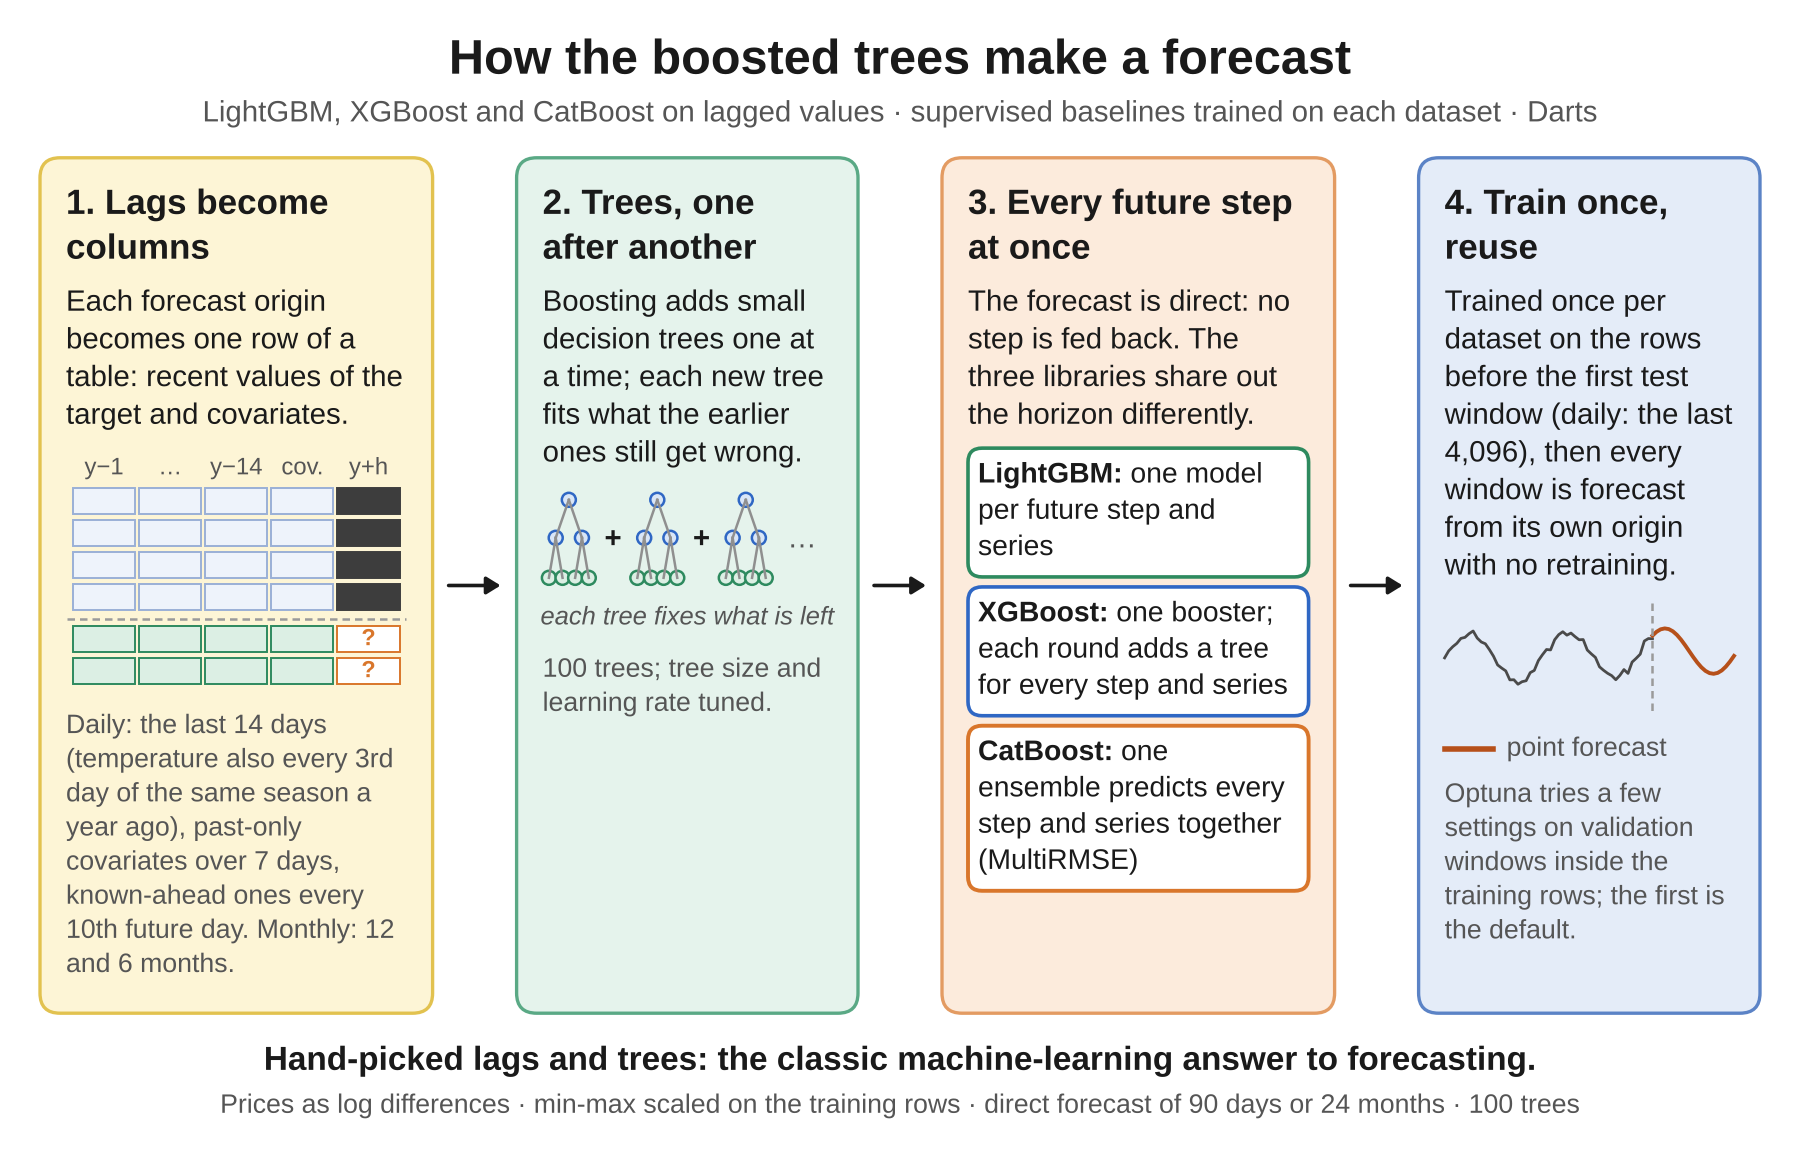

In [15]:
fig = figure("gbdt", path=FIG / "gbdt.png")

#### The maths behind the figure

The figure names the model's main components. Their equations follow, in the order in which the data passes through them.

In **gradient boosting**, the forecast is the sum of $M$ small regression trees $f_m$, each fitted to what the trees before it got wrong and shrunk by the learning rate $\eta$:

$$\hat{y}=\sum_{m=1}^{M}\eta\thinspace f_m(x)$$

In [16]:
run("lightgbm")

,status,seconds,covariates read,hyperparameters,notes
dataset,,,,,
D1,ran,90.4,none,"num_leaves=31, learning_rate=0.05",
D2,ran,25.4,"fourier_sin_1, fourier_cos_1, fourier_sin_2, fourier_cos_2, daylength_h, wav_d1_2, wav_d3_4, wav_d5_6, wav_d7_8, wav_s8, nao, ao","num_leaves=31, learning_rate=0.1",
D3,ran,6.1,none,"num_leaves=31, learning_rate=0.2",
D4,ran,6.1,"global_activity, usd, real_rate_10y","num_leaves=31, learning_rate=0.2",


In [17]:
run("xgboost")

,status,seconds,covariates read,hyperparameters,notes
dataset,,,,,
D1,ran,17.0,none,"max_depth=6, learning_rate=0.1",
D2,ran,53.3,"fourier_sin_1, fourier_cos_1, fourier_sin_2, fourier_cos_2, daylength_h, wav_d1_2, wav_d3_4, wav_d5_6, wav_d7_8, wav_s8, nao, ao","max_depth=6, learning_rate=0.1",
D3,ran,42.3,none,"max_depth=8, learning_rate=0.3",
D4,ran,33.5,"global_activity, usd, real_rate_10y","max_depth=6, learning_rate=0.1",


In [18]:
run("catboost")

,status,seconds,covariates read,hyperparameters,notes
dataset,,,,,
D1,ran,12.9,none,"depth=6, learning_rate=0.1",
D2,ran,35.9,"fourier_sin_1, fourier_cos_1, fourier_sin_2, fourier_cos_2, daylength_h, wav_d1_2, wav_d3_4, wav_d5_6, wav_d7_8, wav_s8, nao, ao","depth=6, learning_rate=0.05",
D3,ran,19.0,none,"depth=6, learning_rate=0.05",
D4,ran,25.3,"global_activity, usd, real_rate_10y","depth=6, learning_rate=0.1",


## 5 · Deep-learning baselines: NHiTS, TFT, DLinear and TiDE

All four are Darts models. Each is trained once per dataset on the rows before the earliest test window, with an
input of 400 days (120 for TFT) or 36 months and an output as long as the longest horizon, and is then applied at
every origin without retraining. Each network writes one value per step and is trained with the mean squared
error, so it gives a point forecast only. The inputs are scaled to the range 0 to 1 with the minimum and maximum of
the training rows only (the default scaler of Darts). For each dataset, the Optuna search of Section 2 picks the width of NHiTS, TFT and TiDE (for DLinear, the moving-average
window) and the learning rate of each, starting from Darts' defaults. The training budget is short (8 to 15 epochs)
to keep the full run within two hours on a CPU. Every network starts from the same seed, but results can still
differ slightly between machines, and between a CPU and a GPU.

### NHiTS

N-HiTS stacks small fully connected blocks. Each block looks at the input at a different sampling rate and forecasts a coarse version of the future, which is then interpolated to full length. Adding up the blocks rebuilds the forecast from the slow components to the fast ones.

#### How to read the figure

Read the figure from left to right. Its four numbered panels follow the data from the series the model reads to the forecast it returns. The bold sentence under the panels sums up what sets the model apart, and the grey line below gives its size and the settings used in this chapter.

#### What it costs to run

Linear in the input length and the horizon: a few small networks that train in seconds to minutes on a CPU.

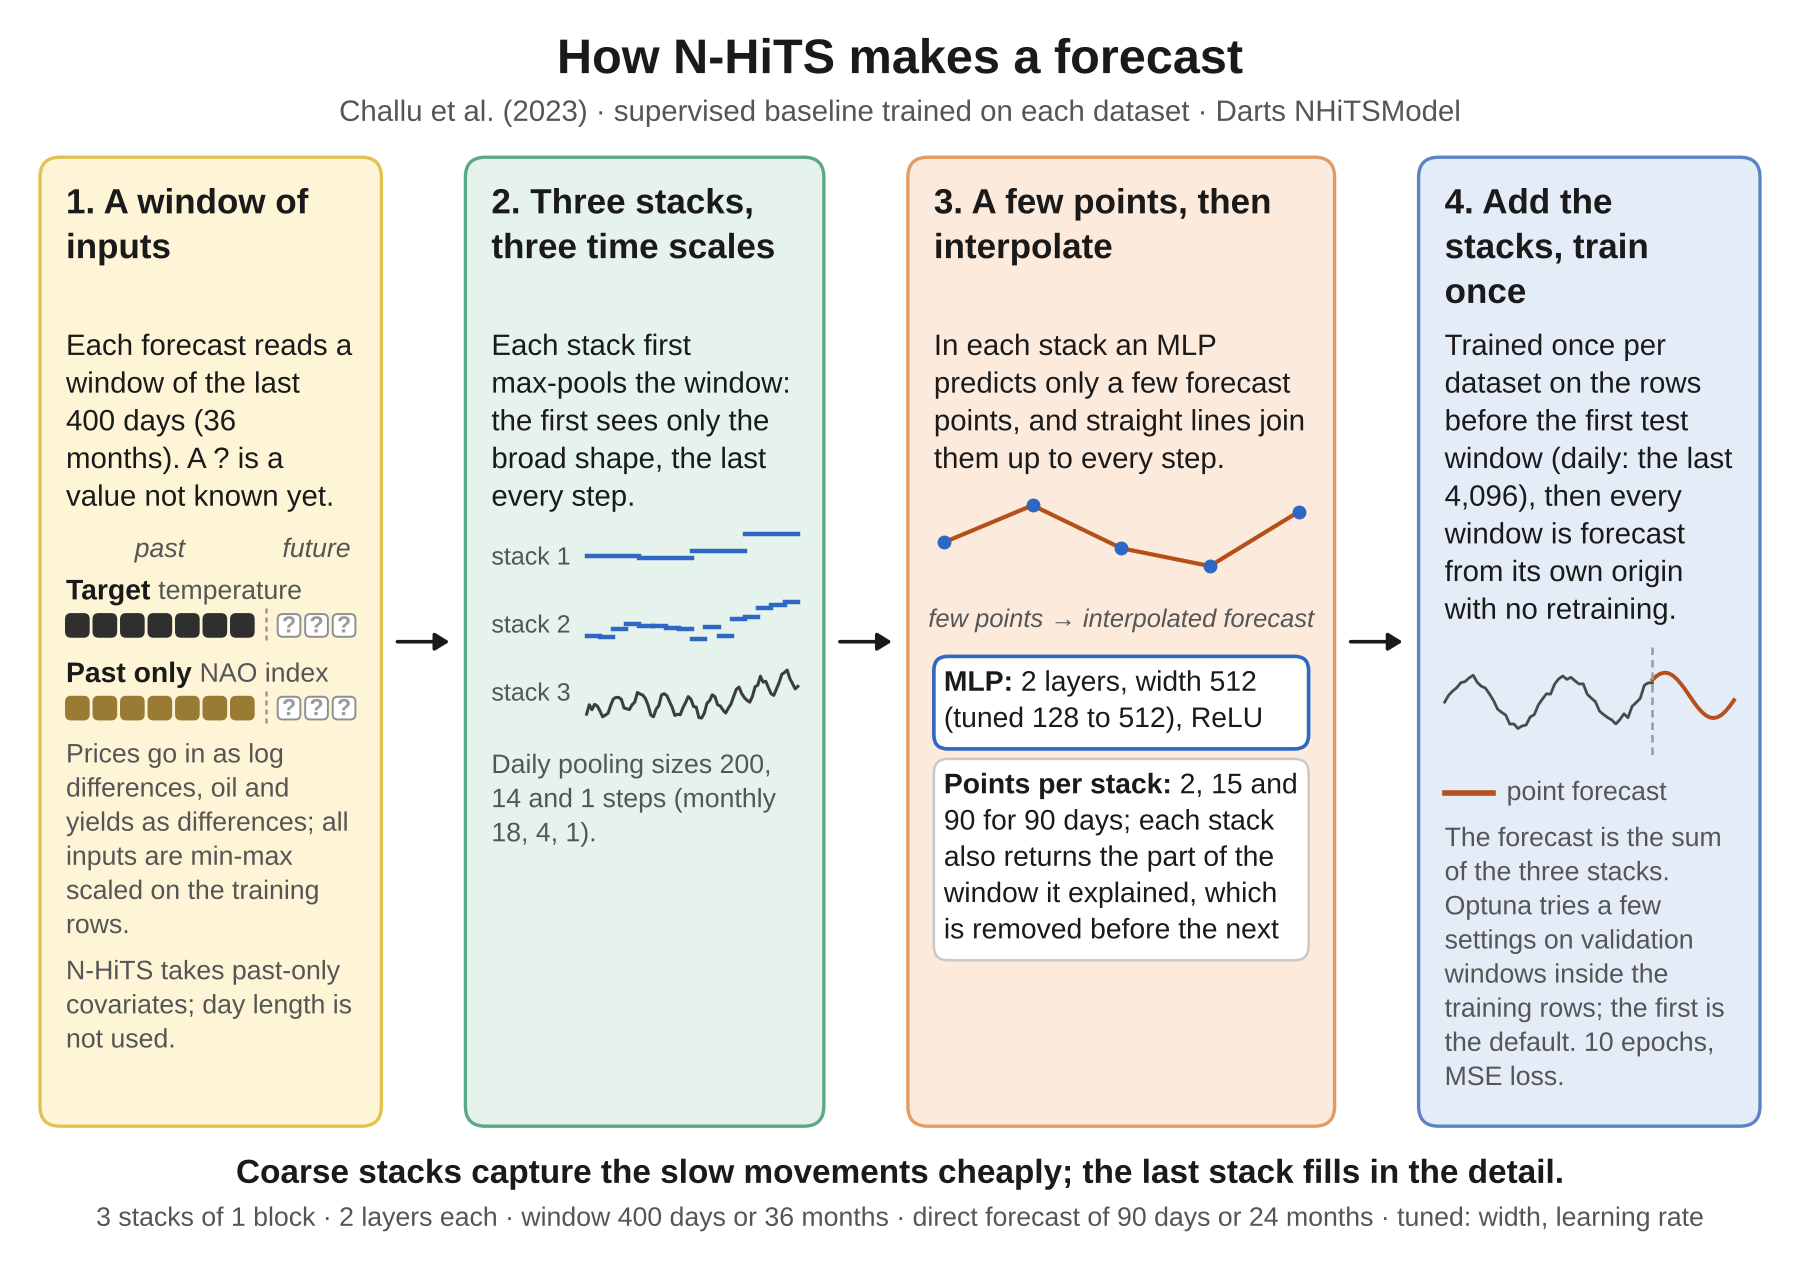

In [19]:
fig = figure("nhits", path=FIG / "nhits.png")

#### The maths behind the figure

The figure names the model's main components. Their equations follow, in the order in which the data passes through them.

In **multi-rate sampling**, each stack sees the input after max-pooling with its own kernel size $k_\ell$:

$$\tilde{y}=\mathrm{MaxPool}_ {k_\ell}(y_{t-L+1:t})$$

A large kernel keeps only the slow movements; a small one keeps the detail.

With **hierarchical interpolation**, a block predicts only a few knots $\theta$ of the future, and the steps $\tau$ between two knots $a$ and $b$ are filled in along a straight line:

$$\hat{y}_ {\tau}=\theta_a+\frac{\tau-\tau_a}{\tau_b-\tau_a}(\theta_b-\theta_a)$$

Long horizons therefore cost little.

#### Where the figure comes from

The figure was checked against the model's paper, its Darts implementation and this chapter's settings. The main sources for its components:

| Component in the figure | Source |
|---|---|
| multi-rate pooling, hierarchical interpolation, residual stacking | Challu et al. 2023 (AAAI), Sec. 3 |

In [20]:
run("nhits")

,status,seconds,covariates read,hyperparameters,notes
dataset,,,,,
D1,ran,1.8,none,"layer_widths=256, lr=0.0003",
D2,ran,1.3,"wav_d1_2, wav_d3_4, wav_d5_6, wav_d7_8, wav_s8, nao, ao","layer_widths=128, lr=0.0003",
D3,ran,0.2,none,"layer_widths=512, lr=0.0003",
D4,ran,0.2,"global_activity, usd, real_rate_10y","layer_widths=256, lr=0.003",


### TFT

The Temporal Fusion Transformer (TFT) combines recurrent layers for local patterns with attention for long-range ones. Its variable selection networks learn a weight for each covariate, which makes it a natural supervised benchmark for the datasets with covariates.

#### How to read the figure

Read the figure from left to right. Its four numbered panels follow the data from the series the model reads to the forecast it returns. The bold sentence under the panels sums up what sets the model apart, and the grey line below gives its size and the settings used in this chapter.

#### What it costs to run

The LSTM costs O(T · d²) and attention O(T² · d) over the encoder and decoder steps; it is the slowest baseline to train.

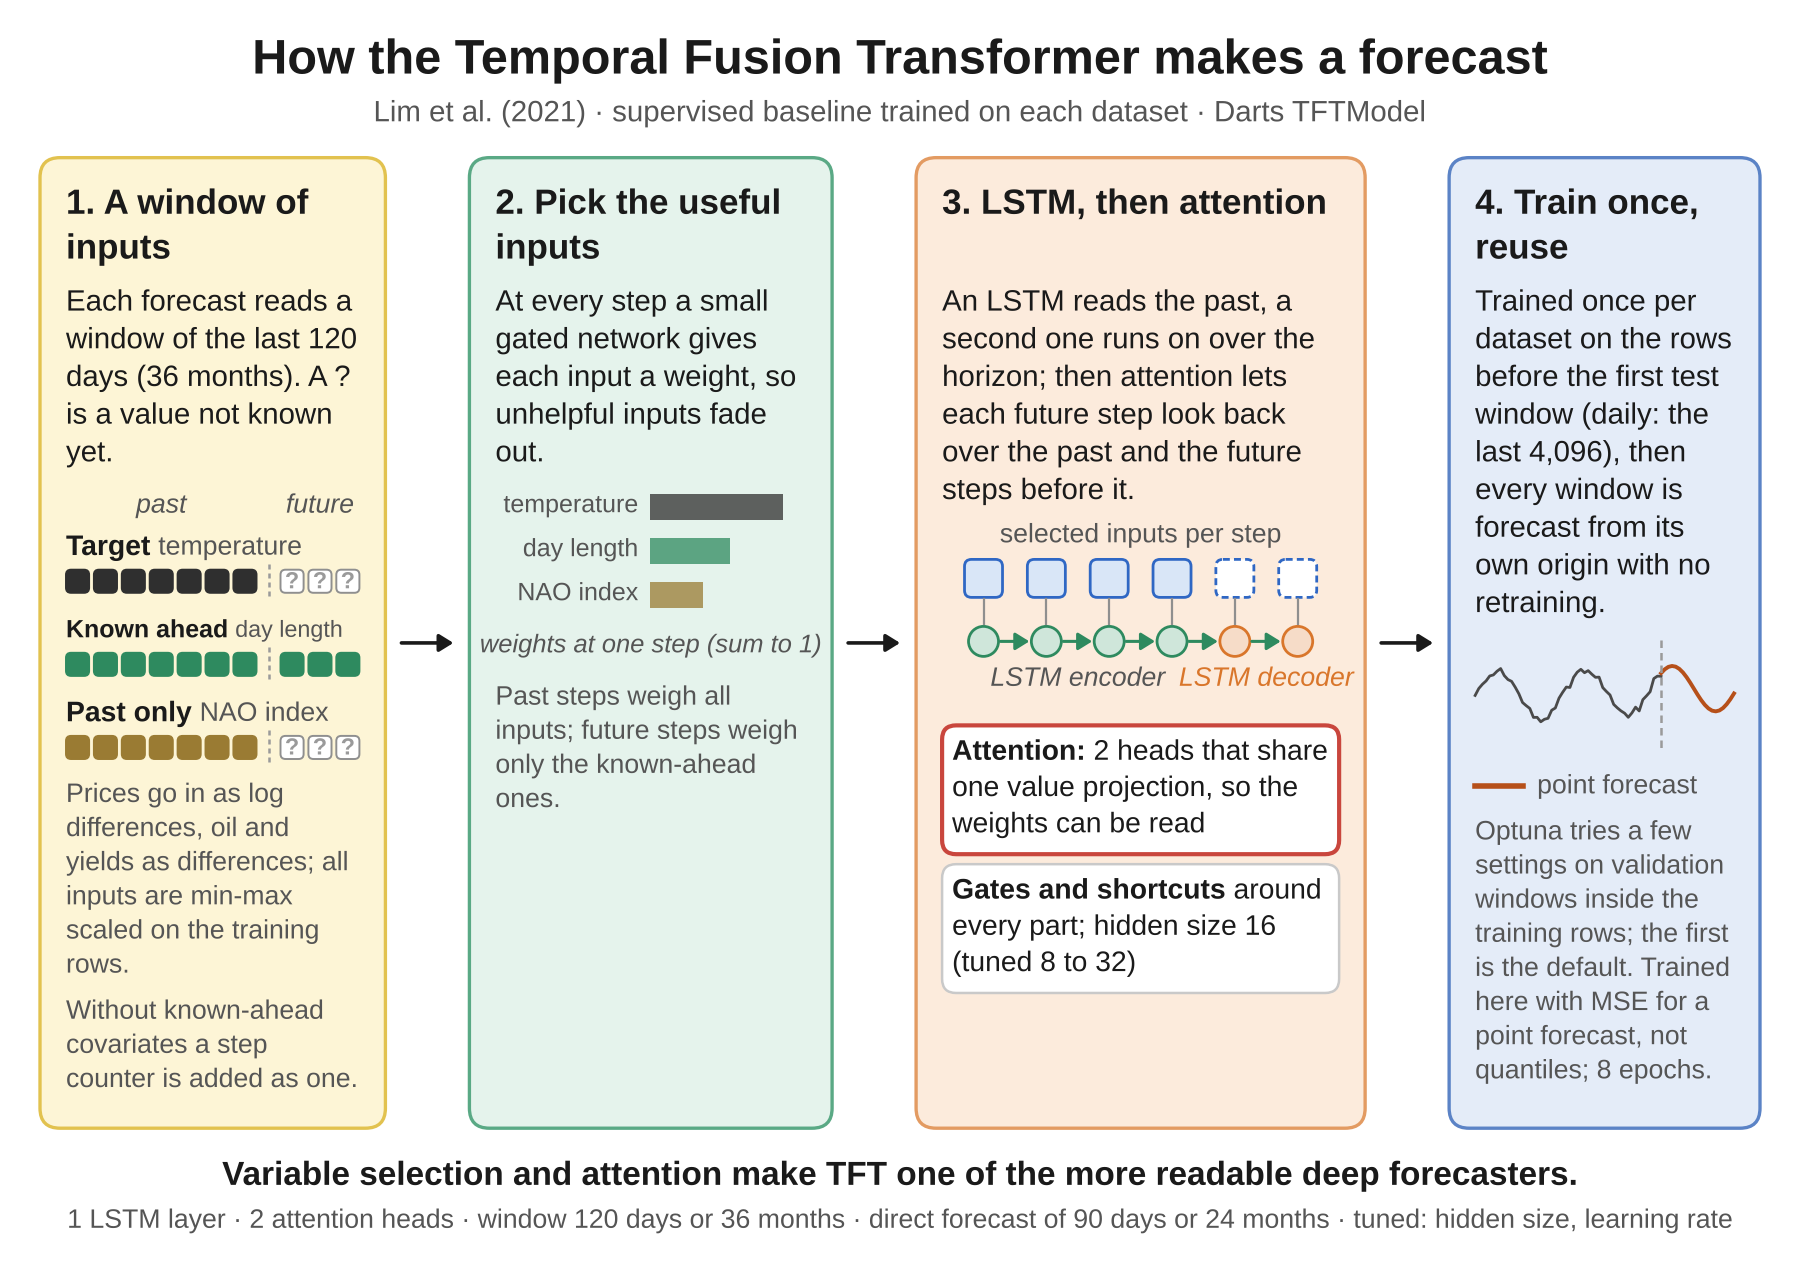

In [21]:
fig = figure("tft", path=FIG / "tft.png")

#### The maths behind the figure

The figure names the model's main components. Their equations follow, in the order in which the data passes through them.

**Masked self-attention** compares each token's query $Q$ with the keys $K$, turns the scores into weights with a softmax, and uses the weights to mix the values $V$:

$$\mathrm{softmax}\left(\frac{QK^{\top}}{\sqrt{d_k}}+M\right)V$$

The mask $M$ is $-\infty$ wherever a token may not read another: a later time step in causal attention, or an excluded pair in variate attention (covariates that may not read targets, or rows that belong to different series). Dividing by $\sqrt{d_k}$, the square root of the key width, keeps the scores in a range where the softmax does not saturate.

#### Where the figure comes from

The figure was checked against the model's paper, its Darts implementation and this chapter's settings. The main sources for its components:

| Component in the figure | Source |
|---|---|
| variable selection, LSTM encoder-decoder, static enrichment, interpretable attention | Lim et al. 2021 (IJF), Sec. 4 and Fig. 2 |
| point output trained with mean squared error (TFT's quantile outputs are switched off here) | baselines.py (likelihood=None); Darts TFTModel |

In [22]:
run("tft")

,status,seconds,covariates read,hyperparameters,notes
dataset,,,,,
D1,ran,9.4,none,"hidden_size=16, lr=0.003",
D2,ran,14.3,"fourier_sin_1, fourier_cos_1, fourier_sin_2, fourier_cos_2, daylength_h, wav_d1_2, wav_d3_4, wav_d5_6, wav_d7_8, wav_s8, nao, ao","hidden_size=16, lr=0.003",
D3,ran,0.7,none,"hidden_size=16, lr=0.003",
D4,ran,1.0,"global_activity, usd, real_rate_10y","hidden_size=16, lr=0.003",


### DLinear

DLinear asks how far a single linear map can go. The input is split into a trend (a moving average) and a remainder, each part is mapped to the horizon by one linear layer, and the two outputs are added.

#### How to read the figure

Read the figure from left to right. Its four numbered panels follow the data from the series the model reads to the forecast it returns. The bold sentence under the panels sums up what sets the model apart, and the grey line below gives its size and the settings used in this chapter.

#### What it costs to run

O(L · H) multiply-adds per forecast, the cheapest neural baseline.

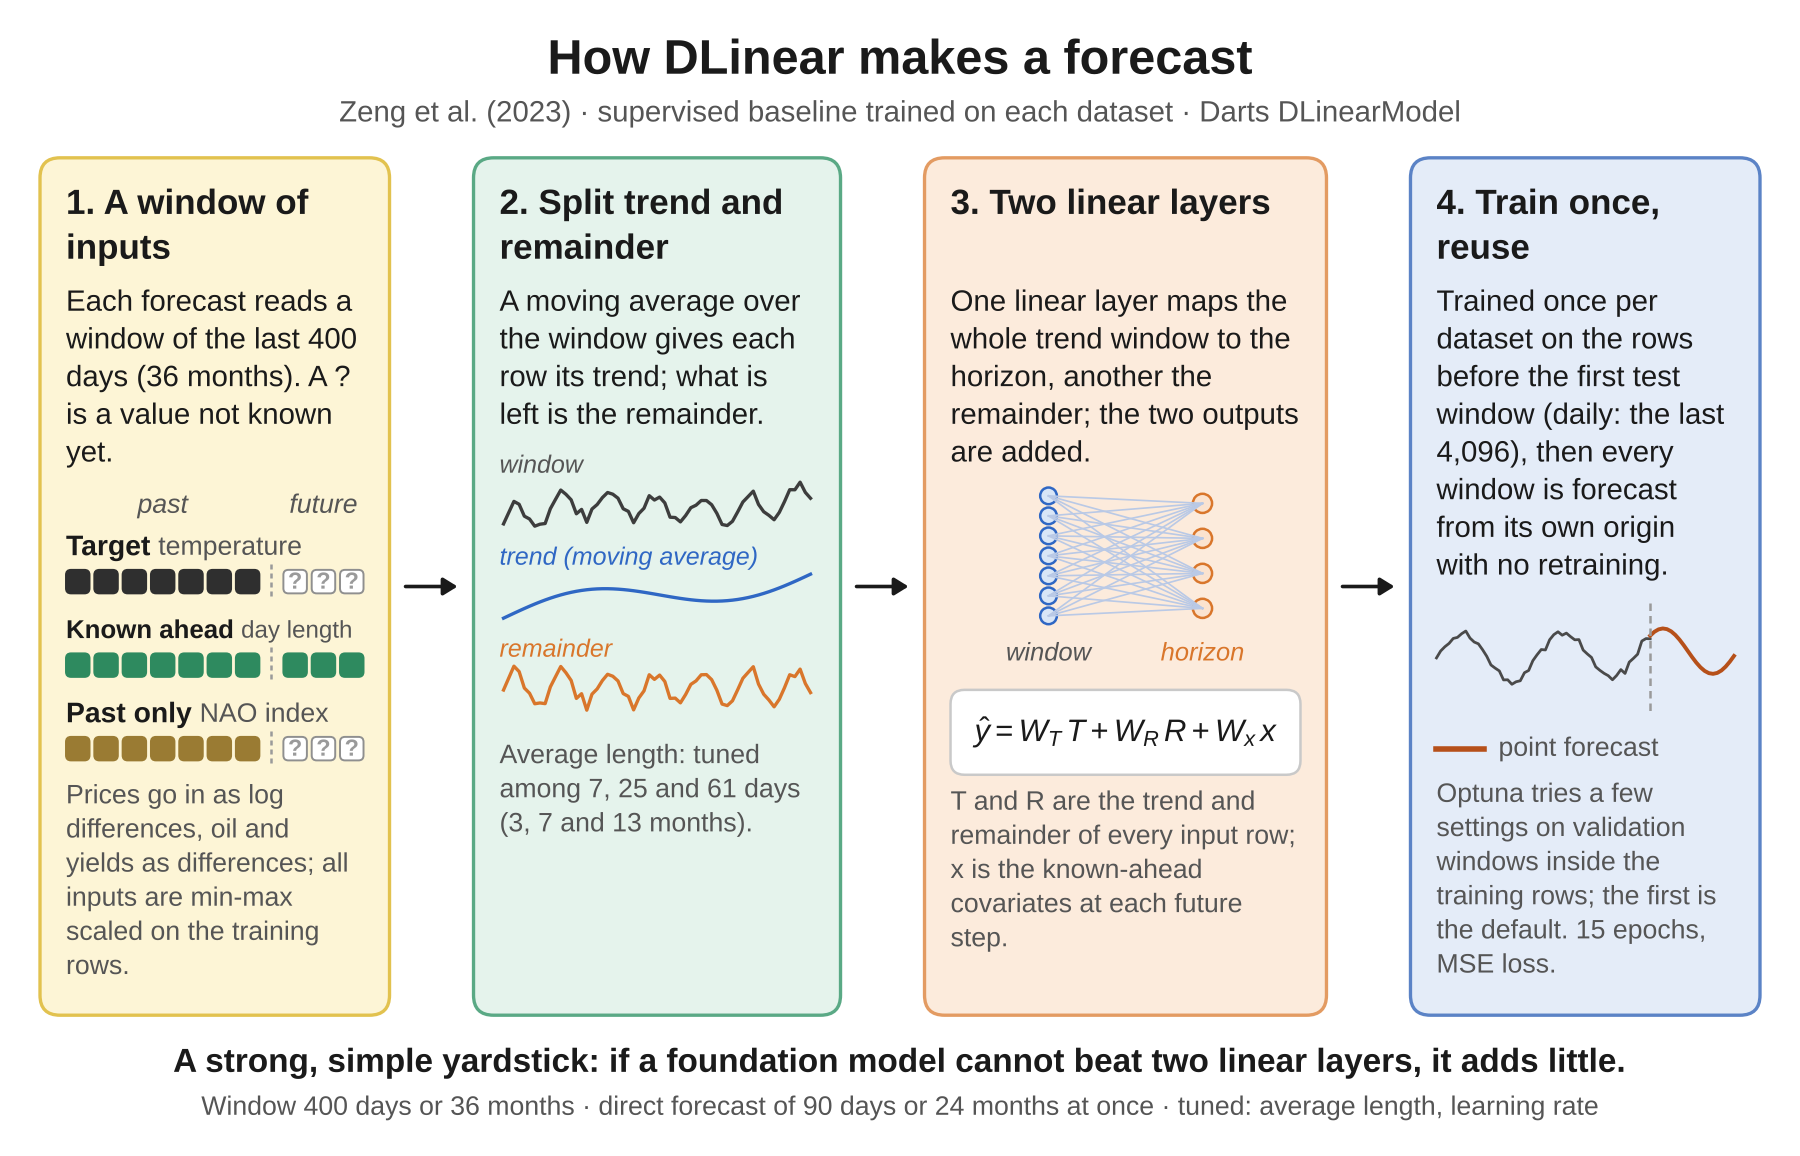

In [23]:
fig = figure("dlinear", path=FIG / "dlinear.png")

#### The maths behind the figure

The figure names the model's main components. Their equations follow, in the order in which the data passes through them.

The **decomposition** splits the input into a trend, computed as a moving average, and the remainder:

$$x=x^{\mathrm{trend}}+x^{\mathrm{rem}}$$

Each part gets its own linear map from the last $L$ values to the next $H$.

#### Where the figure comes from

The figure was checked against the model's paper, its Darts implementation and this chapter's settings. The main sources for its components:

| Component in the figure | Source |
|---|---|
| series decomposition then two one-layer linear networks | Zeng et al. 2023 (AAAI), Sec. 4 |

In [24]:
run("dlinear")

,status,seconds,covariates read,hyperparameters,notes
dataset,,,,,
D1,ran,0.5,none,"kernel_size=7, lr=0.0003",
D2,ran,0.7,"fourier_sin_1, fourier_cos_1, fourier_sin_2, fourier_cos_2, daylength_h, wav_d1_2, wav_d3_4, wav_d5_6, wav_d7_8, wav_s8, nao, ao","kernel_size=7, lr=0.0003",
D3,ran,0.1,none,"kernel_size=7, lr=0.0003",
D4,ran,0.1,"global_activity, usd, real_rate_10y","kernel_size=13, lr=0.0003",


### TiDE

TiDE (Time-series Dense Encoder) answers the question DLinear raised: it keeps the speed of a model built only from fully connected layers, but adds covariates and non-linearity. The look-back and the projected covariates are flattened into one vector, which residual blocks encode and then decode into one small vector per future step. A temporal decoder combines each step's vector with that step's covariates, and a global linear skip from the look-back to the horizon keeps a purely linear forecaster inside the model.

#### How to read the figure

Read the figure from left to right. Its four numbered panels follow the data from the series the model reads to the forecast it returns. The bold sentence under the panels sums up what sets the model apart, and the grey line below gives its size and the settings used in this chapter.

#### What it costs to run

O((L·V + (L+H)·w) · d) for the encoder, where w is the width of the projected covariates, plus O(d · p · H) for the decoder, where p is the size of each step's vector: linear in look-back and horizon, with no attention. Its authors report training 5 to 10 times faster than the best transformer they compared it with.

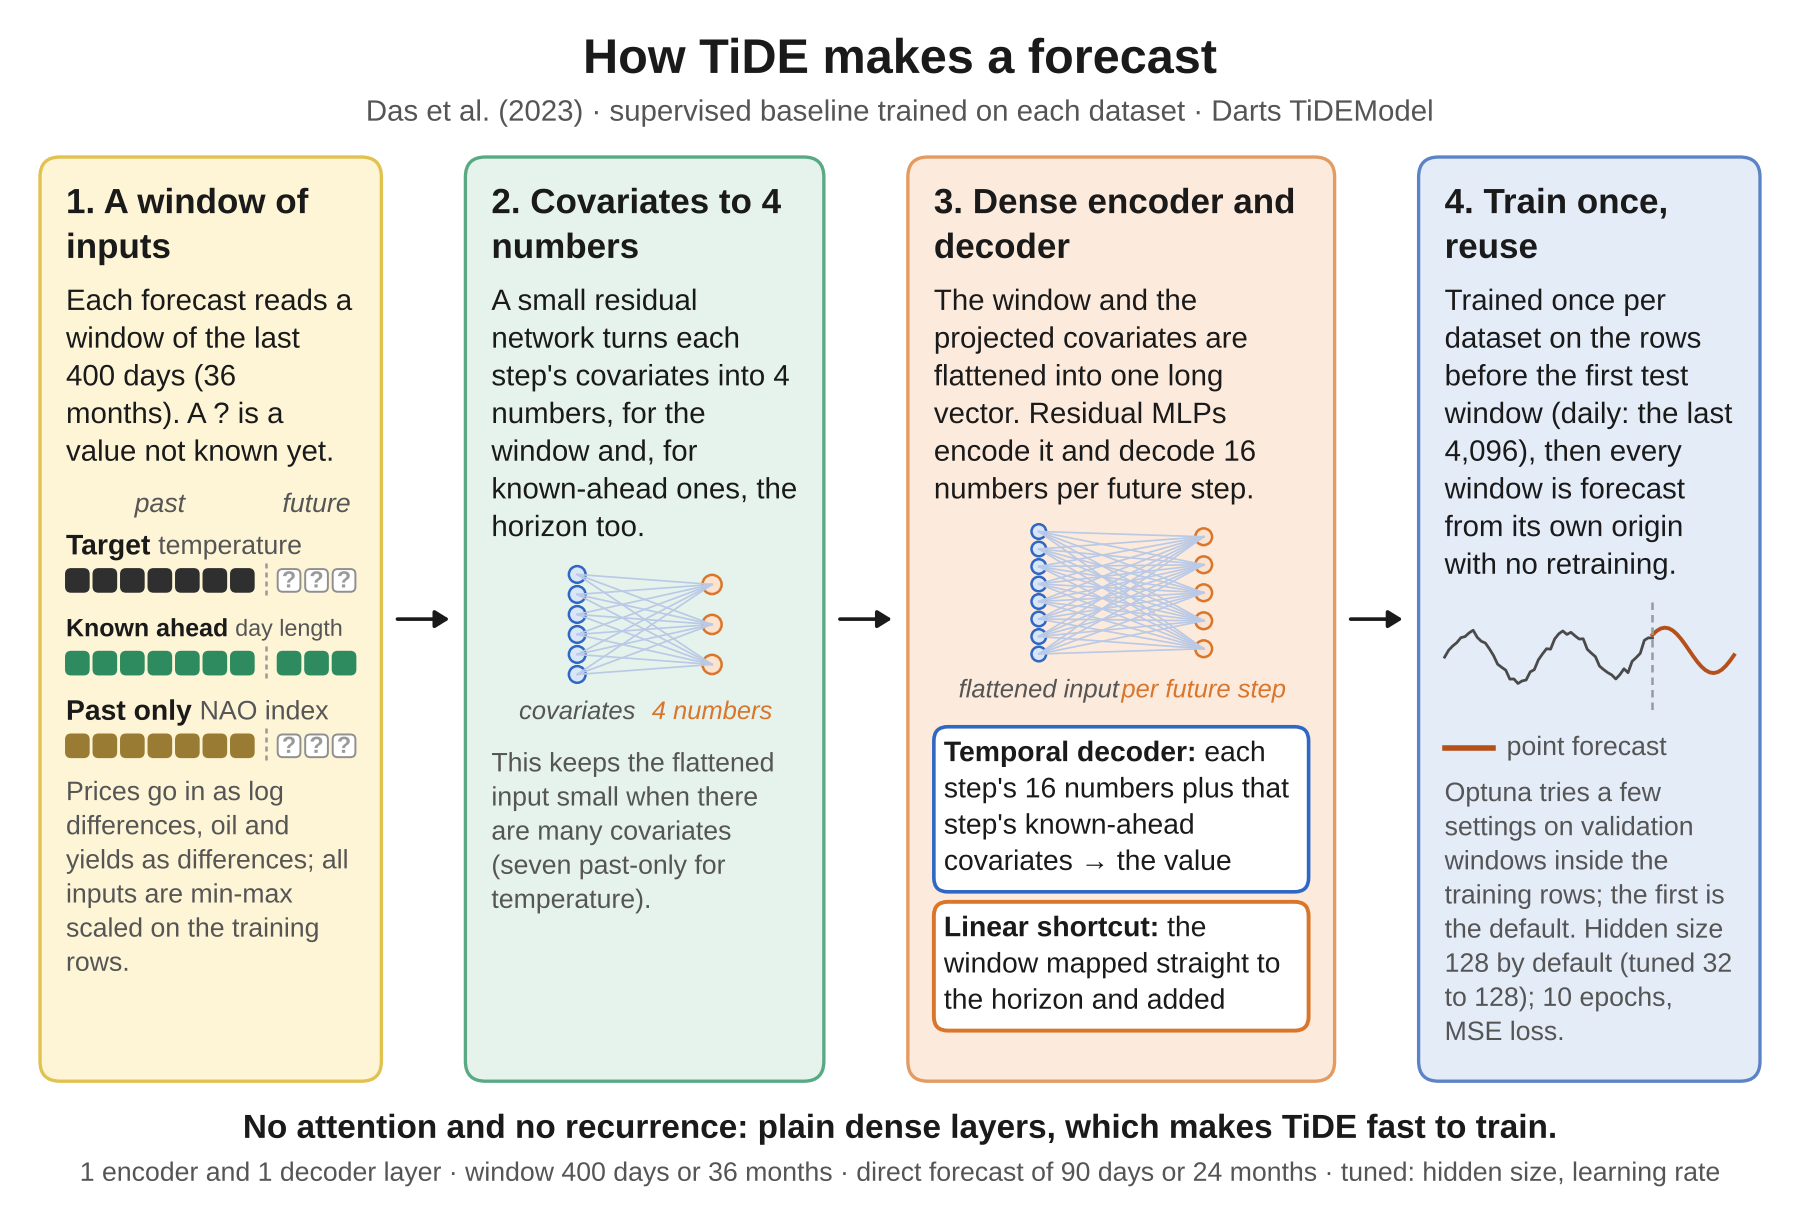

In [25]:
fig = figure("tide", path=FIG / "tide.png")

#### The maths behind the figure

The figure names the model's main components. Their equations follow, in the order in which the data passes through them.

TiDE's **residual block** is a one-hidden-layer ReLU network plus a linear skip $W_sx$ (a matrix, because the input and output widths differ):

$$\mathrm{RB}(x)=\mathrm{Dropout}\left(W_2\thinspace\mathrm{ReLU}(W_1x)\right)+W_sx$$

Every part of TiDE (feature projection, encoder, decoder and temporal decoder) is built from it. The TiDE paper adds a layer norm on the output, which the Darts implementation leaves off by default.

The **global linear skip** adds a single linear map $A$, of size $H \times L$, from the look-back to the horizon to the output $\mathrm{TD}(\cdot)$ of the temporal decoder:

$$\hat{y}_ {L+1:L+H}=\mathrm{TD}(\cdot)+A\thinspace y_{1:L}$$

TiDE therefore contains a purely linear forecaster, like DLinear, and the fully connected network only has to learn what the linear map misses.

#### Where the figure comes from

The figure was checked against the model's paper, its Darts implementation and this chapter's settings. The main sources for its components:

| Component in the figure | Source |
|---|---|
| feature projection, dense encoder, dense decoder, temporal decoder, global residual (linear) connection | Das et al. 2023 (TMLR), Sec. 4 and Fig. 1 |
| residual block: one ReLU hidden layer, linear skip, dropout, layer norm on the output | Sec. 4, Fig. 1 |
| Darts version: all targets in one model, past covariates projected over the look-back, layer norm off by default; widths 4 (covariates), p = 16 (decoder output), 32 (temporal decoder), 1 encoder and 1 decoder block | darts 0.41.0, models/forecasting/tide_model.py (_TideModule) |

In [26]:
run("tide")

,status,seconds,covariates read,hyperparameters,notes
dataset,,,,,
D1,ran,0.9,none,"hidden_size=128, lr=0.001",
D2,ran,2.7,"fourier_sin_1, fourier_cos_1, fourier_sin_2, fourier_cos_2, daylength_h, wav_d1_2, wav_d3_4, wav_d5_6, wav_d7_8, wav_s8, nao, ao","hidden_size=64, lr=0.003",
D3,ran,0.3,none,"hidden_size=32, lr=0.003",
D4,ran,0.1,"global_activity, usd, real_rate_10y","hidden_size=32, lr=0.003",


## 6 · What the hyperparameter search chose

One row per learned baseline and dataset: the validation MASE of the default setting (trial 0), the setting Optuna
chose and its validation MASE, the gain over the default, the number of trials, how long the search took and where it
ran. A gain near 0% means the defaults were already as good as anything in the value lists. The validation windows lie
inside the training data, so these numbers are not test scores and can rank the models differently from Section 7.

In [27]:
tuning_summary(ROOT, KEYS, DATASETS)

validation MASE (default)                             chosen  validation MASE (chosen)  gain over default %  trials  search seconds device
model    dataset                                                                                                                                            
LightGBM D1                          0.8230  num_leaves=31, learning_rate=0.05                    0.8121                  1.3       4            96.4    cpu
         D2                          0.6875   num_leaves=31, learning_rate=0.1                    0.6875                  0.0       4           291.4    cpu
         D3                          4.8774   num_leaves=31, learning_rate=0.2                    4.4536                  8.7       4            41.6    cpu
         D4                          4.4081   num_leaves=31, learning_rate=0.2                    4.1547                  5.7       4            48.3    cpu
XGBoost  D1                          0.9389     max_depth=6, learning_rate=0.1                    0.8316                 11.4       3           180.6    cpu
         D2                          0.7478     max_depth=6, learning_rate=0.1                    0.6955                  7.0       3           579.3    cpu
         D3                          4.7941     max_depth=8, learning_rate=0.3                    4.5874                  4.3       3           183.3    cpu
         D4                          4.8350     max_depth=6, learning_rate=0.1                    4.4756                  7.4       3           197.5    cpu
CatBoost D1                          0.7230         depth=6, learning_rate=0.1                    0.7230                  0.0       2            88.8    cpu
         D2                          0.7080        depth=6, learning_rate=0.05                    0.7048                  0.5       2           279.8    cpu
         D3                          4.6195        depth=6, learning_rate=0.05                    4.5296                  1.9       2           152.3    cpu
         D4                          4.2226         depth=6, learning_rate=0.1                    4.2226                  0.0       2           184.8    cpu
NHiTS    D1                          0.8039        layer_widths=256, lr=0.0003                    0.7391                  8.1       5            39.2    cpu
         D2                          0.9272        layer_widths=128, lr=0.0003                    0.7985                 13.9       5            76.5    cpu
         D3                          5.5576        layer_widths=512, lr=0.0003                    4.8422                 12.9       5             4.9    cpu
         D4                          4.5783         layer_widths=256, lr=0.003                    4.2322                  7.6       5             5.1    cpu
TFT      D1                          1.4900           hidden_size=16, lr=0.003                    0.7876                 47.1       3           144.2    cpu
         D2                          0.7554           hidden_size=16, lr=0.003                    0.7325                  3.0       3           346.9    cpu
         D3                          8.6041           hidden_size=16, lr=0.003                    4.8498                 43.6       3            10.2    cpu
         D4                          5.1362           hidden_size=16, lr=0.003                    4.7152                  8.2       3            12.0    cpu
DLinear  D1                          0.7710           kernel_size=7, lr=0.0003                    0.7396                  4.1       6            30.5    cpu
         D2                          0.9048           kernel_size=7, lr=0.0003                    0.7826                 13.5       6            71.9    cpu
         D3                          5.8668           kernel_size=7, lr=0.0003                    4.7461                 19.1       6             2.6    cpu
         D4                          6.3766          kernel_size=13, lr=0.0003               

Every trial of every search, with its setting and validation MASE (saved as `results/tables/table_baseline_tuning.csv`).

In [28]:
trials = tuning_results(ROOT, KEYS, DATASETS)
trials.to_csv(RESULTS / "tables" / "table_baseline_tuning.csv", index=False)
trials.set_index(["model", "dataset", "trial"])

setting  validation MASE chosen  seconds
model    dataset trial                                                                          
CatBoost D1      0          default: depth=6, learning_rate=0.1           0.7230    yes     44.7
                 1                  depth=6, learning_rate=0.05           0.7622            44.1
DLinear  D1      0            default: kernel_size=25, lr=0.001           0.7710             5.3
                 1                    kernel_size=25, lr=0.0003           0.7455             5.2
                 2                     kernel_size=25, lr=0.003           0.7832             5.1
...                                                         ...              ...    ...      ...
TiDE     D4      2                     hidden_size=64, lr=0.003           5.1877             0.7
                 4                     hidden_size=32, lr=0.003           5.1072    yes      1.0
XGBoost  D4      0      default: max_depth=6, learning_rate=0.3           4.8350            49.0
                 1               max_depth=6, learning_rate=0.1           4.4756    yes     90.8
                 2               max_depth=8, learning_rate=0.3           4.9468            57.7

[108 rows x 4 columns]

## 7 · Results of the full runs

MASE and RMSE, averaged over the series and rolling windows of each dataset and horizon. Below 1 means better than
the naive rule used for scaling, and the best value of each row is in bold. Notebook 11 puts these numbers next to
the foundation models.

#### MASE by dataset and horizon

A dash (–) marks a baseline that was not run on that dataset, never a failed run: the VAR needs several target
series and no covariates (D3 only); ARIMAX, ARDL and the VARX need covariates (D2 and D4; the VARX, being
multivariate, only D4). On D2 and D4 a baseline that cannot read the covariates gets exactly its D1 or D3 input, so
its rows there repeat its D1 or D3 rows.

In [29]:
fc = load_forecasts(ROOT, KEYS, DATASETS)
agg = aggregate(scores_cached(ROOT, KEYS, DATASETS))
show_horizon_table(agg, "MASE", KEYS, NAMES)

#### RMSE by dataset and horizon

The same table for the root mean squared error. Squaring the errors before averaging makes the RMSE weigh large
misses more than the MASE does, so a model that is usually close but sometimes far off looks worse here. To average over the five metals, whose prices differ by a factor of about ten,
the mean squared error (MSE) of the forecast is divided by the mean squared error of the naive rule on the history,
and the square root of the ratio is taken. The result is the root mean squared scaled error (RMSSE), whose weighted
form was the accuracy metric of the M5 forecasting competition:

$$\mathrm{MSE} = \frac{1}{H}\sum_{h=1}^{H}\left(y_{T+h}-\hat y_{T+h}\right)^2, \qquad \mathrm{MSE}_ {\text{naive}} = \frac{1}{T-\ell}\sum_{t=\ell+1}^{T}\left(y_t-y_{t-\ell}\right)^2,$$

$$\mathrm{RMSSE} = \sqrt{\mathrm{MSE} / \mathrm{MSE}_ {\text{naive}}}.$$

Below 1 again means smaller errors than the naive rule made on the history. Notebook 11 shows
the RMSE in the units of the data for every series.

In [30]:
show_horizon_table(agg, "RMSSE", KEYS, NAMES)

#### Actual values against the forecasts

There is one figure per dataset, with one row of panels per series (all five metals on D3 and D4) and one panel per horizon. Each
panel shows the recent history (grey), what actually happened (black) and the point forecast of one baseline of each kind (change `SHOW` to pick others from the list in Section 1), all from
the same test window. Window 1 is the most recent one and ends at the last observation, so the longer horizons
start further back in time. To show fewer series, change `SERIES` (for example to `"copper"` for one metal); to look at an older
window, change `WINDOW` (daily data has 5 rolling windows, monthly data 3, and 1 at 24 months). On D2 and D4 only the models that read the covariates are drawn: the others'
forecasts are identical to their D1 or D3 forecasts.

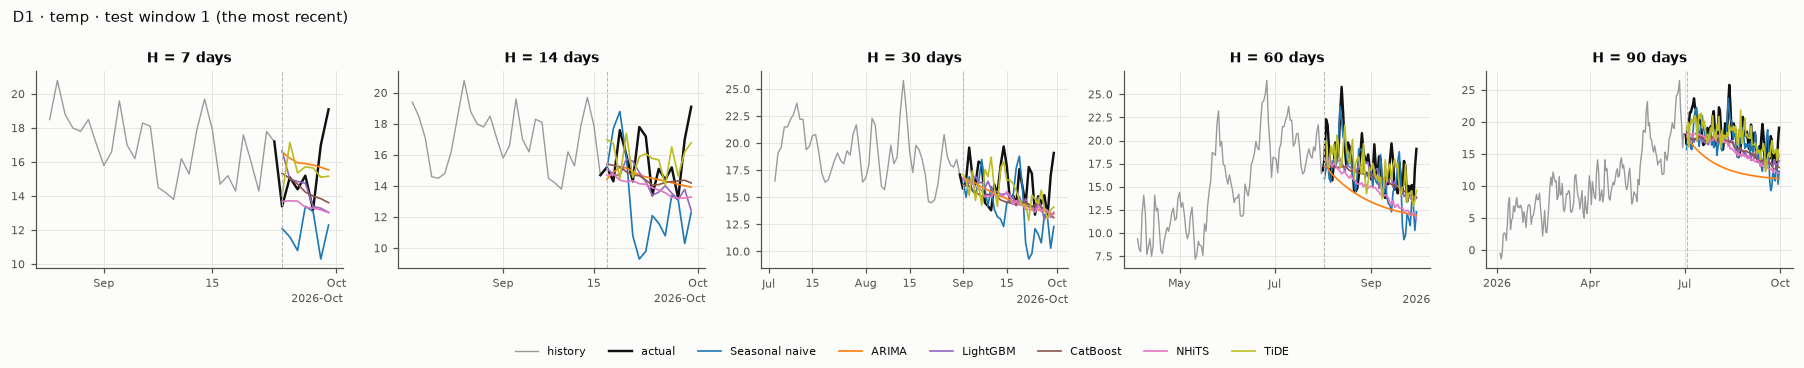

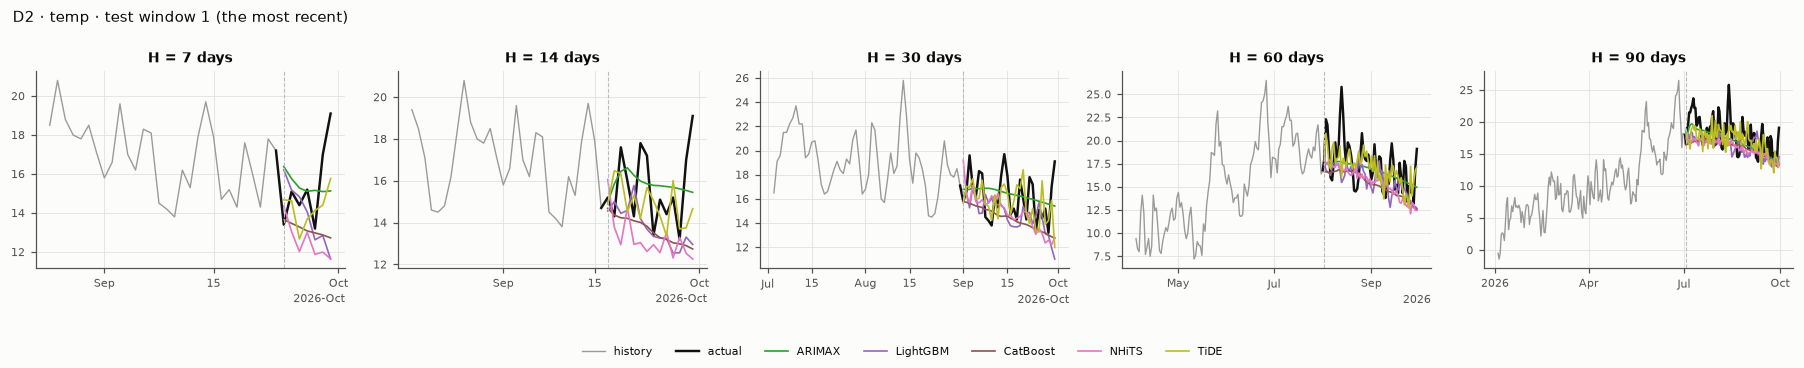

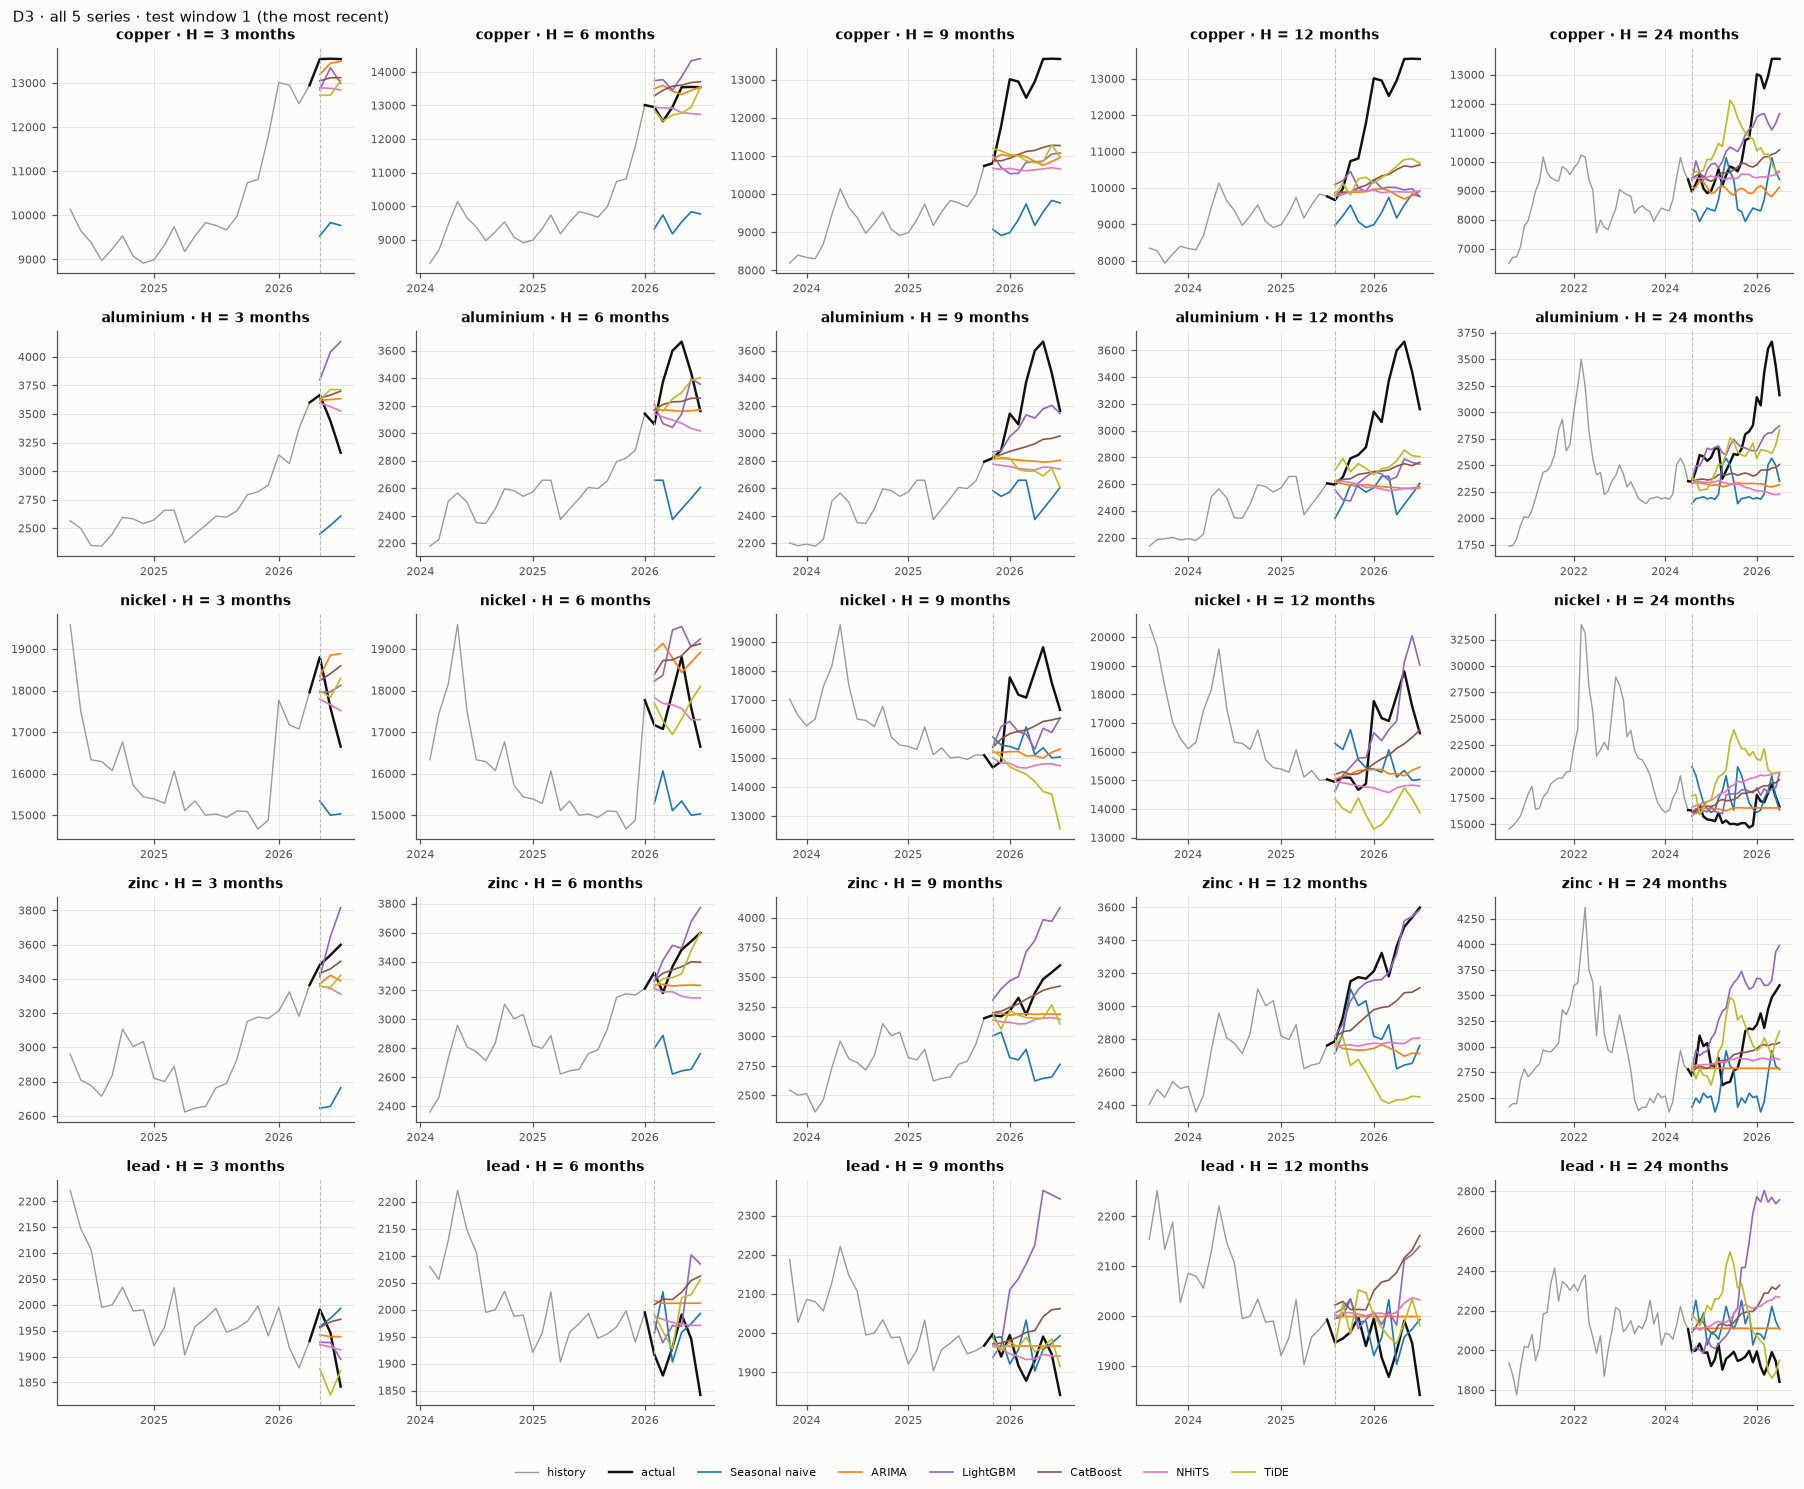

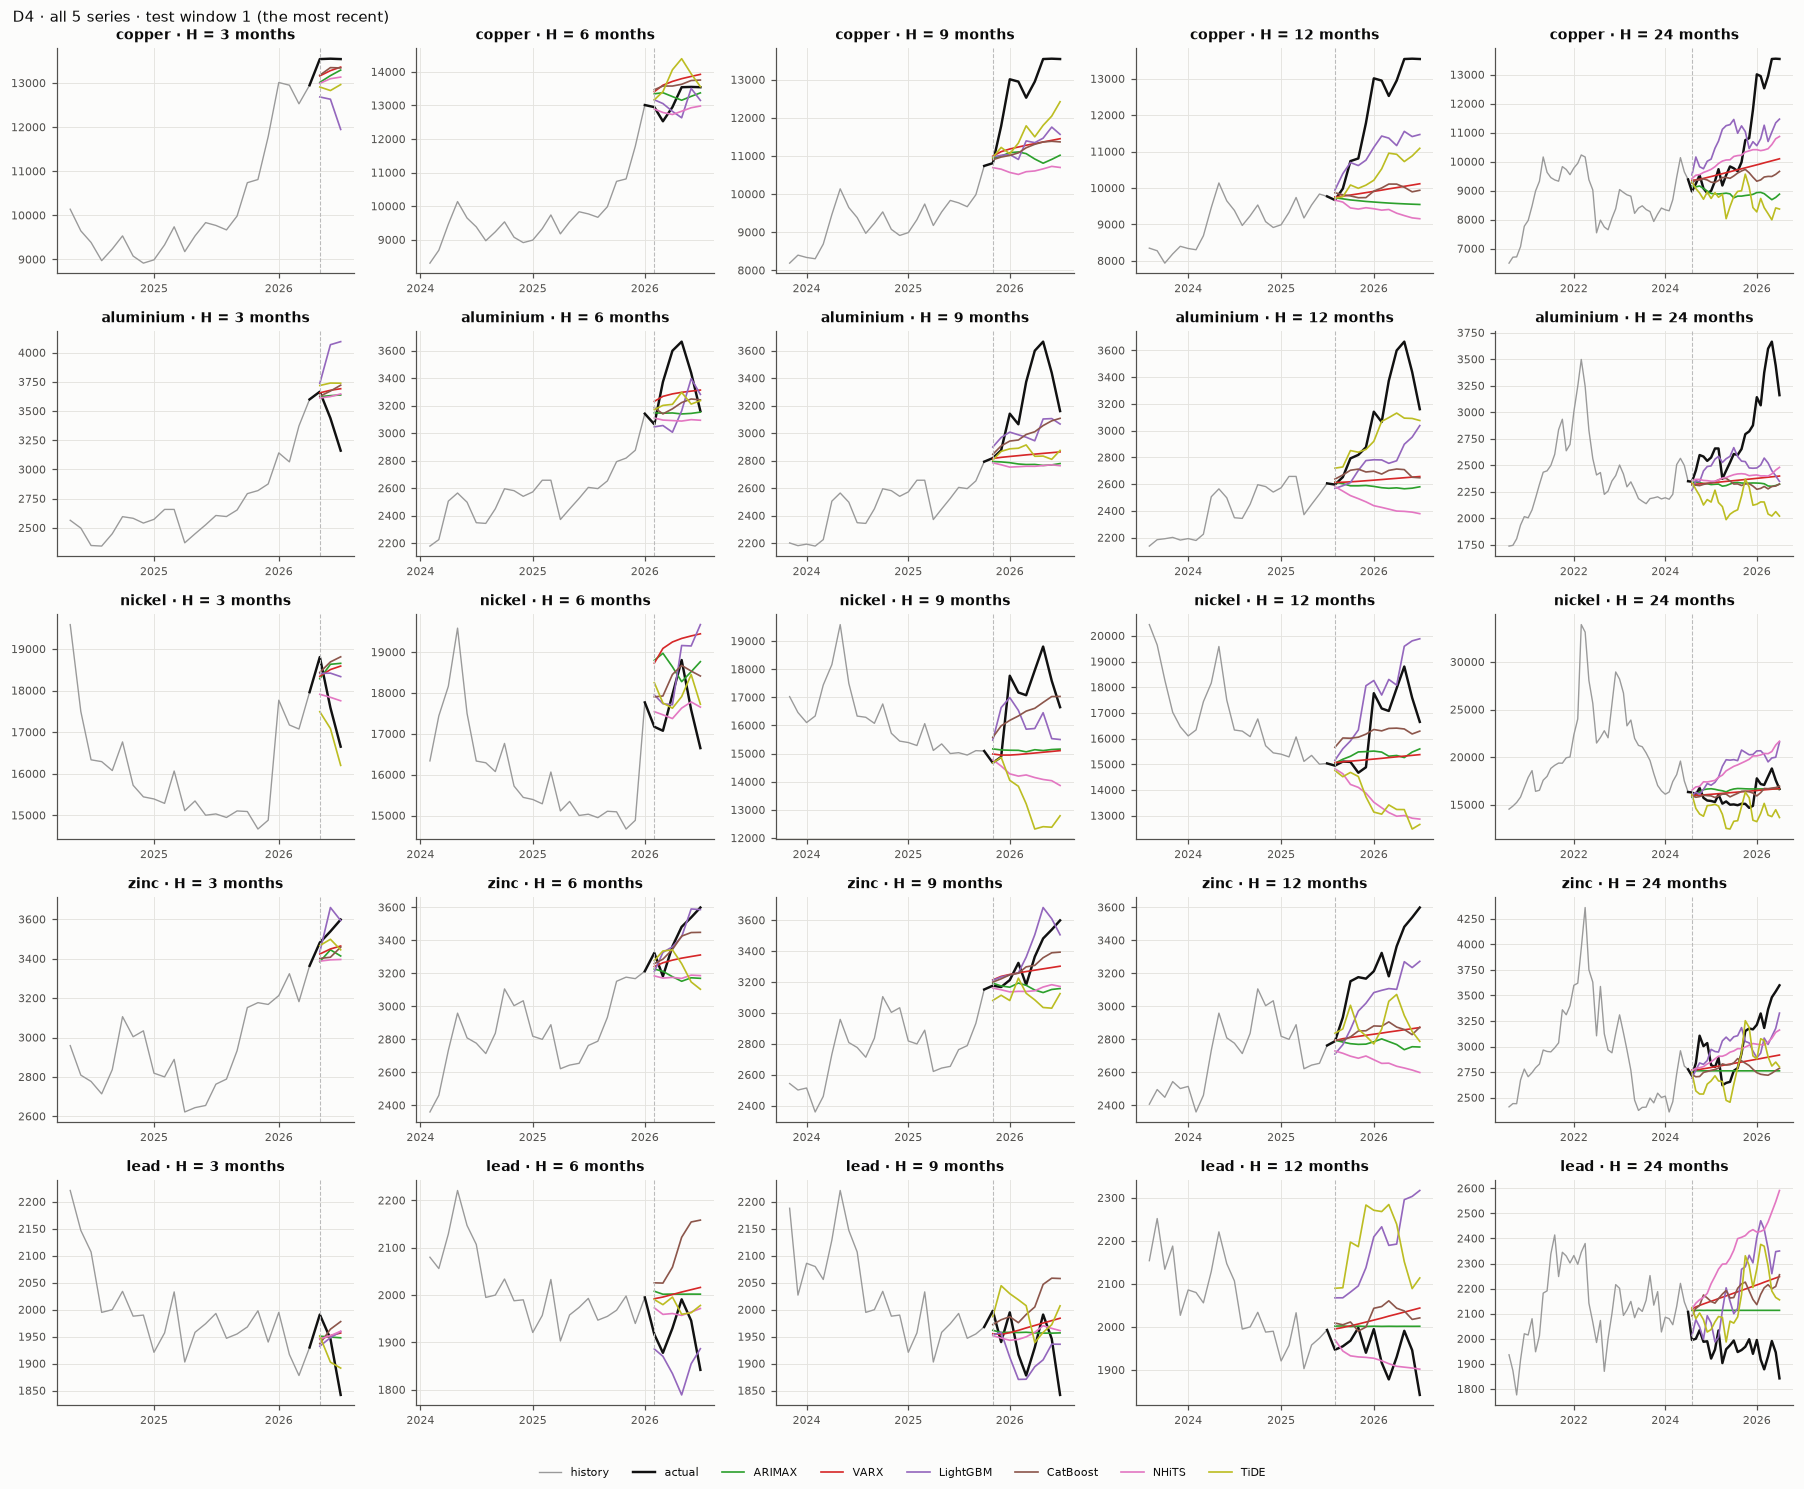

In [31]:
SHOW = ["snaive", "arima", "arimax", "varx", "lightgbm", "catboost", "nhits", "tide"]
# the series to show: "all", one name or a list of names;
# D3 and D4 hold copper, aluminium, nickel, zinc and lead
SERIES = {"D1": "temp", "D2": "temp", "D3": "all", "D4": "all"}
WINDOW = 1  # 1 = the most recent test window
frames = {d: load_frame(ROOT, d) for d in DATASETS}
figs = forecast_gallery(fc, frames, SERIES, [k for k in SHOW if k in KEYS], NAMES, window=WINDOW)

#### The forecasts in numbers

For each dataset, the table shows the actual values and the point forecast of each baseline in `SHOW` at one horizon of the same test window, with the naive rule added for reference.
`SERIES` and `WINDOW` work as in the plots above, so there is one table per series; change `HORIZON` to see another
horizon. In each row the forecast closest to the actual value is in bold. The grey rows underneath summarise the
window: the MAE, the RMSE and the mean error ME = mean(actual − forecast), which is positive when the forecasts were
too low. The best value of each is in bold. One window is a small sample, so these numbers can rank the models
differently from the averages over all windows in the tables above. Every horizon of the window is saved as a CSV
file in `results/tables/forecast_vs_actual/`.

In [32]:
HORIZON = {"D1": 14, "D2": 14, "D3": 6, "D4": 6}   # D1, D2: 7, 14, 30, 60 or 90 days; D3, D4: 3, 6, 9, 12 or 24 months
show_forecast_tables(fc, SERIES, HORIZON, ["naive"] + [k for k in SHOW if k in KEYS], NAMES, window=WINDOW, datasets=list(frames),
                     save=RESULTS / "tables" / "forecast_vs_actual" / "10.csv")

**D1 · temp · H = 14 days · test window 1** (2026-09-17 to 2026-09-30)

,actual,Naive (RW),Seasonal naive,ARIMA,LightGBM,CatBoost,NHiTS,TiDE
2026-09-17,15.20,14.70,15.10,14.44,15.13,15.41,14.71,17.00
2026-09-18,14.30,14.70,17.70,14.89,14.75,15.33,14.77,16.75
2026-09-19,17.60,14.70,18.80,15.19,14.68,15.24,14.38,14.48
2026-09-20,16.00,14.70,15.90,15.17,15.74,14.92,14.28,17.40
2026-09-21,14.30,14.70,10.80,14.93,15.60,14.70,14.34,14.55
2026-09-22,17.80,14.70,9.30,14.71,14.87,14.67,14.15,15.88
2026-09-23,17.20,14.70,9.80,14.59,14.28,14.38,14.11,16.09
2026-09-24,13.40,14.70,12.10,14.50,13.41,14.06,13.89,15.78
2026-09-25,15.10,14.70,11.60,14.41,13.61,14.09,13.75,15.68
2026-09-26,14.40,14.70,10.80,14.32,14.01,14.23,13.57,14.06


**D2 · temp · H = 14 days · test window 1** (2026-09-17 to 2026-09-30)

,actual,Naive (RW),Seasonal naive,ARIMAX,LightGBM,CatBoost,NHiTS,TiDE
2026-09-17,15.20,14.70,15.10,14.97,14.55,14.68,16.06,14.87
2026-09-18,14.30,14.70,17.70,15.85,15.01,14.36,13.78,16.48
2026-09-19,17.60,14.70,18.80,16.45,14.44,14.23,12.94,16.34
2026-09-20,16.00,14.70,15.90,16.62,14.58,14.20,14.73,14.51
2026-09-21,14.30,14.70,10.80,16.26,15.78,14.09,12.96,15.31
2026-09-22,17.80,14.70,9.30,15.99,14.19,14.01,13.04,14.21
2026-09-23,17.20,14.70,9.80,15.86,13.69,13.83,12.62,15.68
2026-09-24,13.40,14.70,12.10,15.78,13.34,13.51,12.94,15.05
2026-09-25,15.10,14.70,11.60,15.76,13.26,13.28,12.57,14.31
2026-09-26,14.40,14.70,10.80,15.72,13.24,13.20,13.53,13.36


**D3 · copper · H = 6 months · test window 1** (2026-02-01 to 2026-07-01)

,actual,Naive (RW),Seasonal naive,ARIMA,LightGBM,CatBoost,NHiTS,TiDE
2026-02-01,"12,951","13,012","9,331","13,501","13,740","13,288","12,951","12,862"
2026-03-01,"12,529","13,012","9,740","13,602","13,769","13,451","12,925","12,539"
2026-04-01,"12,951","13,012","9,177","13,429","13,459","13,575","12,926","12,716"
2026-05-01,"13,543","13,012","9,533","13,329","13,858","13,604","12,785","12,770"
2026-06-01,"13,552","13,012","9,835","13,448","14,330","13,683","12,760","12,955"
2026-07-01,"13,543","13,012","9,771","13,550","14,393","13,708","12,737","13,537"
MAE,,368,"3,614",404,747,373,463,285
RMSE,,427,"3,634",538,801,483,579,412
ME (actual - forecast),,166,"3,614",-298,-747,-373,331,282


... (15 outputs left out)

,actual,Naive (RW),Seasonal naive,ARIMAX,VARX,LightGBM,CatBoost,NHiTS,TiDE
2026-02-01,"3,324","3,213","2,800","3,226","3,241","3,211","3,259","3,185","3,278"
2026-03-01,"3,182","3,213","2,889","3,212","3,264","3,328","3,286","3,171","3,336"
2026-04-01,"3,364","3,213","2,622","3,180","3,280","3,361","3,345","3,176","3,342"
2026-05-01,"3,482","3,213","2,644","3,152","3,292","3,422","3,426","3,169","3,259"
2026-06-01,"3,539","3,213","2,655","3,173","3,302","3,590","3,447","3,189","3,148"
2026-07-01,"3,599","3,213","2,763","3,170","3,311","3,587","3,448","3,186","3,104"
MAE,,212,686,240,161,64,81,236,222
RMSE,,246,718,280,180,82,91,272,281
ME (actual - forecast),,202,686,229,133,-1,46,236,171


**D4 · lead · H = 6 months · test window 1** (2026-02-01 to 2026-07-01)

,actual,Naive (RW),Seasonal naive,ARIMAX,VARX,LightGBM,CatBoost,NHiTS,TiDE
2026-02-01,"1,917","1,995","1,957","2,008","1,992","1,886","2,026","1,973","1,990"
2026-03-01,"1,878","1,995","2,033","2,002","1,996","1,871","2,025","1,959","1,980"
2026-04-01,"1,930","1,995","1,903","2,002","2,001","1,834","2,059","1,961","1,996"
2026-05-01,"1,991","1,995","1,958","2,002","2,006","1,789","2,122","1,957","1,959"
2026-06-01,"1,946","1,995","1,974","2,002","2,011","1,855","2,154","1,964","1,963"
2026-07-01,"1,842","1,995","1,993","2,002","2,016","1,887","2,158","1,972","1,978"
MAE,,78,72,86,87,79,174,58,71
RMSE,,91,92,98,100,101,188,69,82
ME (actual - forecast),,-78,-52,-86,-87,64,-174,-47,-60


Every horizon of window 1 saved to /home/user/v3/results/tables/forecast_vs_actual/10.csv


#### Do the covariates help, by MASE and by RMSE?

For every baseline that reads covariates (ARIMAX, ARDL and the VARX run only with covariates, so they are compared with their plain twins ARIMA, AR and VAR), the tables give the % change in the error when the model gets the covariates:
D2 (the twelve temperature covariates) against D1, and D4 (three drivers, past values only) against D3. Negative
(green) means the covariates helped, positive (red) that they hurt. The MASE change says whether the typical error
shrank; the RMSE change, because it squares the errors, says whether the large misses shrank. When the two
disagree, the covariates helped with one kind of error only.

Three points help in reading the tables:

- **Daily and monthly results are in separate tables.** D2 against D1 is scored at 7 to 90 days and the metals at
  3 to 24 months. In one shared table every daily row would have empty cells (NaN, "not a number") under the monthly
  horizons and every monthly row under the daily ones: there was nothing to compute there, not a failed run.
- **A model is listed only where it read covariates.** A model that cannot read a kind of covariate ignores it, so
  its D2 or D4 forecasts are identical to its D1 or D3 forecasts and there is no gain to report. For example
  TimesFM-2.5 (Notebook 05a) reads only known-future covariates: it appears on D2, whose annual harmonics and day
  length are known in advance, but not on D4, whose drivers are past-only.
- **The RMSE change is measured series by series.** For temperature it is exactly the change in RMSE; for the
  metals it is the change in the scaled RMSE (RMSSE), so that nickel, at about 16,000 dollars a tonne, does not
  outweigh lead at about 2,000. An "n/a" would mark a horizon a model did not run.

In [33]:
gains = gain_tables(agg, KEYS, NAMES)
show_gains(gains)

**Daily temperature, D2 against D1 (horizons in days)**: % change in MASE and in RMSE when the model reads the covariates

**Monthly metals, D4 against D3 (horizons in months)**: % change in MASE and in RMSE when the model reads the covariates

**MASE against RMSE**: mean change over the horizons, and at how many horizons each metric improves

#### What the runs cost

The time in seconds for all horizons and windows, including the hyperparameter search and the training of the learned models. 0.0 means the baseline reads none of that dataset's covariates, so its D1 or D3 forecasts were reused; a dash (–) means it was not run there, for the reasons given under the MASE table.

In [34]:
runs = run_summary(ROOT, KEYS)
cost_table(runs, DATASETS)

dataset,D1,D2,D3,D4
model,,,,
AR,39.3,0.0,1.7,0.0
ARDL,–,189.9,–,25.5
ARIMA,27.5,0.0,208.7,0.0
ARIMAX,–,230.3,–,150.9
CatBoost,135.8,414.6,227.9,278.1
DLinear,35.6,83.0,3.2,3.8
LightGBM,117.5,358.4,54.3,63.3
NHiTS,47.4,89.6,6.7,6.5
Naive (RW),0.1,0.0,0.1,0.0


## 8 · Key insights


- **On temperature the tuned baselines come close to the foundation models, but none beats the best.** DLinear reaches
  a mean MASE of 0.684 on D1, 1.8% behind Chronos-Bolt (0.672) and level with TiRex (0.684). XGBoost, LightGBM and
  CatBoost follow at 0.716 to 0.719, TiDE at 0.738 and NHiTS at 0.772, all ahead of the seasonal naive rule (0.858).
  TFT (0.921) and ARIMA (1.038) are behind it. ARIMA has no seasonal term for daily data, so it cannot carry the annual
  cycle beyond a few weeks (1.27 to 1.32 at 30 to 90 days).
- **Covariates help the linear models; most learned models get worse.** With D2's covariates ARDL scores 0.675 (0.48
  at 7 days, 0.73 at 90), level with the best foundation models, and ARIMAX improves on ARIMA by 29% on average over
  the horizons (mean MASE 0.708 against 1.038), from 9% at 7 days to 39% at 90 days: the calendar terms give it the
  annual cycle that ARIMA lacks. Of the learned
  models only TFT gains (15% on average) and TiDE is level (-0.6%). DLinear gets 33% worse, XGBoost and LightGBM 14% to
  15%, CatBoost 11% and NHiTS 7%. Their lags of the same days last year already carry the season, and for the tree
  models the covariates add more than a hundred lagged inputs. Overfitting is the likely reason; this notebook does not test it.
- **On metals CatBoost has the lowest mean MASE of all 36 models.** It scores 2.545 on D3, level with Chronos-Bolt
  (2.562), the best foundation model, and 8% below the random walk (2.758). The random walk with drift (2.679) and the
  VAR (2.719) also beat the random walk; the other learned baselines do not (DLinear 2.870 to TFT 3.787). The best
  model depends on the metal: CatBoost on copper (tied with Chronos-Bolt) and zinc, TFT on aluminium, and two
  foundation models on lead (TiRex) and nickel (Kairos). The seasonal naive rule is again the worst (5.38).
- **Past-only drivers help TFT most.** On D4 TFT improves on its D3 score by 14% to 31% at every horizon (mean 3.00
  against 3.79), XGBoost by 5% on average and the VARX by about 2% on the VAR. ARIMAX is level with ARIMA (1% worse
  on average, between 3% better and 4% worse at each horizon). NHiTS gets 8% worse, CatBoost 7%, and ARDL is 15%
  behind the AR model. The VARX (2.654) is the best baseline on D4: level with the
  random walk at 3 months and ahead of it from 6 to 24 months.
- **Tuning on validation windows is honest, not always kind.** Across the 42 searches of Notebooks 10 and B10, the
  default setting stayed best 9 times, and the median search lowered the validation MASE by 7.6%. On D1 TFT gained most
  (validation MASE 1.49 with the default learning rate, 0.79 with 0.003), yet it is the weakest learned model on D1's
  test windows (0.921). Two validation windows per dataset are a small sample; the test windows are never consulted.
- **RMSE gives the same verdicts as MASE.** In the gain tables the two metrics move in the same direction in 90 of
  the 95 baseline cells (comparison, model and horizon). The five exceptions are changes below 3.2% (NHiTS on D2 at
  60 days, TiDE on D2 at 14 days, and CatBoost, ARIMAX and the VARX on D4 at 3 months). By RMSSE, CatBoost (1.929) and
  Chronos-Bolt (1.926) swap places on D3, a tie either way; on D1 DLinear (0.680) stays behind Moirai-2.0 (0.665) and
  Chronos-Bolt (0.672).
- **Choosing orders and settings takes most of the time.** With 2 CPU threads, the rules need under a second. Choosing orders at every origin costs AR 39 s on D1,
  ARIMA 28 s on D1 and 209 s on D3, ARIMAX 230 s on D2 and ARDL 190 s on D2. The slowest learned runs, searches
  included, are XGBoost (713 s), TFT (464 s) and CatBoost (415 s), all on D2. `FULL_RUN = True` took 85 minutes in all.

## References

- Benchmark rules and ARIMA (Section 3): Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3rd ed.), OTexts (naive, seasonal naive, drift, ARIMA, regression with ARIMA errors). Free online: [otexts.com/fpp3](https://otexts.com/fpp3/).
- The Hyndman–Khandakar algorithm for ARIMA (Sections 2 and 3): Hyndman, R. J., & Khandakar, Y. (2008). Automatic time series forecasting: the forecast package for R. *Journal of Statistical Software*, 27(3). [doi:10.18637/jss.v027.i03](https://doi.org/10.18637/jss.v027.i03)
- AIC (Section 2): Akaike, H. (1974). A new look at the statistical model identification. *IEEE Transactions on Automatic Control*, 19(6), 716-723 (AIC). [doi:10.1109/TAC.1974.1100705](https://doi.org/10.1109/TAC.1974.1100705)
- AICc (Section 2): Hurvich, C. M., & Tsai, C.-L. (1989). Regression and time series model selection in small samples. *Biometrika*, 76(2), 297-307 (AICc). [doi:10.1093/biomet/76.2.297](https://doi.org/10.1093/biomet/76.2.297)
- Rolling-origin evaluation (Section 2): Tashman, L. J. (2000). Out-of-sample tests of forecasting accuracy: an analysis and review. *International Journal of Forecasting*, 16(4), 437-450 (rolling-origin evaluation, keeping test data out of model selection). [ScienceDirect](https://www.sciencedirect.com/science/article/pii/S0169207000000650)
- Optuna (Section 2): Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). Optuna: a next-generation hyperparameter optimization framework. *KDD 2019*, 2623-2631. [doi:10.1145/3292500.3330701](https://doi.org/10.1145/3292500.3330701)
- The tree-structured Parzen estimator (Section 2): Bergstra, J., Bardenet, R., Bengio, Y., & Kégl, B. (2011). Algorithms for hyper-parameter optimization (tree-structured Parzen estimator, TPE). *NIPS 24*, 2546-2554. No DOI; [Proceedings](https://proceedings.nips.cc/paper_files/paper/2011/file/86e8f7ab32cfd12577bc2619bc635690-Paper.pdf)
- ARDL (Section 3): Pesaran, M. H., & Shin, Y. (1998). An autoregressive distributed-lag modelling approach to cointegration analysis. In S. Strøm (Ed.), *Econometrics and Economic Theory in the 20th Century: The Ragnar Frisch Centennial Symposium* (pp. 371-413). Cambridge University Press. [doi:10.1017/CCOL521633230.011](https://doi.org/10.1017/CCOL521633230.011)
- VAR (Section 3): Sims, C. A. (1980). Macroeconomics and reality. *Econometrica*, 48(1), 1-48. [doi:10.2307/1912017](https://doi.org/10.2307/1912017)
- Gradient boosting (Section 4): Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. *Annals of Statistics*, 29(5), 1189-1232. [doi:10.1214/aos/1013203451](https://doi.org/10.1214/aos/1013203451)
- LightGBM (Section 4): Ke, G. et al. (2017). LightGBM: a highly efficient gradient boosting decision tree. *NeurIPS 30*, 3146-3154. [Proceedings](https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html)
- XGBoost (Section 4): Chen, T., & Guestrin, C. (2016). XGBoost: a scalable tree boosting system. *KDD 2016*, 785-794. [doi:10.1145/2939672.2939785](https://doi.org/10.1145/2939672.2939785)
- CatBoost (Section 4): Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 31*, 6638-6648. [Proceedings](https://proceedings.neurips.cc/paper/2018/hash/14491b756b3a51daac41c24863285549-Abstract.html)
- NHiTS (Section 5): Challu, C. et al. (2023). NHITS: neural hierarchical interpolation for time series forecasting. *AAAI 37*(6). [doi:10.1609/aaai.v37i6.25854](https://doi.org/10.1609/aaai.v37i6.25854)
- TFT (Section 5): Lim, B., Arik, S. O., Loeff, N., & Pfister, T. (2021). Temporal Fusion Transformers for interpretable multi-horizon time series forecasting. *International Journal of Forecasting*, 37(4), 1748-1764. [doi:10.1016/j.ijforecast.2021.03.012](https://doi.org/10.1016/j.ijforecast.2021.03.012)
- DLinear (Section 5): Zeng, A., Chen, M., Zhang, L., & Xu, Q. (2023). Are transformers effective for time series forecasting? *AAAI 37*(9), 11121-11128. [doi:10.1609/aaai.v37i9.26317](https://doi.org/10.1609/aaai.v37i9.26317)
- TiDE (Section 5): Das, A., Kong, W., Leach, A., Mathur, S., Sen, R., & Yu, R. (2023). Long-term forecasting with TiDE: time-series dense encoder. *Transactions on Machine Learning Research*. No DOI; [arXiv:2304.08424](https://arxiv.org/abs/2304.08424)
- The Darts library (Sections 4 and 5): Herzen, J. et al. (2022). Darts: user-friendly modern machine learning for time series. *JMLR*, 23(124), 1-6. [jmlr.org/papers/v23/21-1177](https://jmlr.org/papers/v23/21-1177.html)